# Bounce optical state from A–B–A with the 22/12 recovery (v4)

**Author:** Aaron Roodman (with Claude)
**Date Created:** 2026-11-21
**Last Modified:** 2026-11-21
**Status:** In Progress
**Keywords:** bounce, A–B–A, DZ, v-modes, DOF, 22/12, truncated SVD, BLOCK-T720

## Description

The BLOCK-T720 elevation sweep (reference 70 deg), recovered with the 22-DOF,
12-mode (22/12) scheme instead of RBR 50/50:

1. The A–B–A Δ of all 126 DZ_kj terms for each (night, leg), as in v2.
2. The 22 DOF from the truncated SVD of the 126 × 22 normalized sensitivity, 12
   modes kept: `ΔDOF = N V_12 Σ_12^-1 U_12^T ΔDZ`. The same solve as the 22/12 arm
   of `run_bounce` (`invert_truncated`).
3. Those DOF in the 12 v-modes of the `rubinwork.aos_state` 22-DOF StateEstimator.
4. The ΔDZ the 22/12 fit leaves, `ΔDZ − U_12 U_12^T ΔDZ`, against the RBR 50/50
   residual of `bounce_aba_optical_state_v3`.

22/12 is the scheme the AOS can run from the corner wavefront sensors (CWFS) of
science visits. The input here is the full-focal-plane FAM ΔDZ, so this shows how
much of the bounce signal 22/12 can represent, not the CWFS noise.

Errors: the v2 noise model and Monte Carlo (white Σ_W from the B−A pairs for all
terms, red noise for DZ(1,4)). The 22/12 solve is linear, so each draw maps through
one matrix.

**Output:** `bounce_aba_optical_state_22_12.pdf` (description page first) and CSVs in
the study run directory.

**Based on:** `bounce_aba_optical_state_v2` (legs, noise model), `_v3` (RBR 50/50
residuals, the comparison).

## Change Log

| Date | Author | Description |
|------|--------|-------------|
| 2026-11-21 | Aaron Roodman | v4: 22/12 truncated recovery, 12 v-modes and 22 DOF, residual against RBR 50/50 |

## Table of Contents

1. [Parameters](#params)
2. [Setup & Imports](#setup)
3. [Data Access and the 22/12 decomposition](#data)
4. [Visits and legs](#visits)
5. [Noise model](#model)
6. [A–B–A Δ, 22/12 recovery and Monte Carlo errors](#mc)
7. [How well 22/12 represents the ΔDZ](#resid)
8. [Plots: v-modes, DOF, residuals and DZ vs elevation](#plots)
9. [Description page](#intro)
10. [Save](#save)

<a id='params'></a>
## Parameters

In [1]:
DAY_OBS = [20260418, 20260419, 20260513, 20260709, 20260711, 20260713]
BOUNCE = 'T720_elevation'          # bounce name from analysis_config.yaml

PARAM_SET = 'danish_1_3'
MI_NAME = 'pathA_50_50_i_rbr_5rot'
MIW_VARIANT = 'd13-A_50_50_i_rbr_5rot'
MIW_BUILD = '20261028b'
MIN_DETECTORS = 160                # the bounce run's --min-detectors

T0_MIN = 10.0                      # red-noise reference lag, min
LAG_BINS = [0, 4, 8, 15, 30, 60, 120]   # same-setting variogram bins, min
RBR_RUN = '20261104_aba_dz_residual'    # v3 run: RBR 50/50 DOF and residuals, for comparison
N_MC = 1000                        # MC realisations per (night, leg)
J_PER_PAGE = 4                     # DZ pages: k = 1..6 across, this many j down
SEED = 20261102                    # the v2 seed, so the noise draws match v2
SAVE = True

from rubinwork.common import study_run
run = study_run('aos/bounce', 'aba_optical_state_22_12')

<a id='setup'></a>
## Setup & Imports

In [2]:
import textwrap
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy.optimize import least_squares
from sklearn.covariance import ledoit_wolf

from rubinwork import aos_state
from rubinwork.bounce import legs as bl
from rubinwork.bounce import analysis as ba
from rubinwork.common.utils import repo_root
from rubinwork.products import catalog
from lsst.ts.intrinsic.wavefront.ofc_svd import build_ofc_svd, project_dz_table, LABELS_50DOF

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

<a id='data'></a>
## Data Access and the 22/12 decomposition

The fit table goes through the same bad-fit drop and quality cut as the bounce run.
`P22` is the linear 22/12 map from ΔDZ (126) to ΔDOF (22), built by applying
`invert_truncated` to each unit DZ vector. `PI = F22 P22` is the projector onto
the 12 retained u-modes, so the fitted ΔDZ is `PI ΔDZ`.

Hexapod tilts are in deg. (`DOF_UNITS_50` says arcsec; that label is stale.)

In [3]:
cfg = bl.resolve_config(PARAM_SET, MI_NAME,
                        analysis_config=repo_root() / 'aos' / 'analysis_config.yaml')
prefix = cfg['fit_prefix']
b = next(x for x in cfg['bounces'] if x['name'] == BOUNCE)
ft = ba.load_fit_table(catalog.path('miw', MIW_VARIANT, build=MIW_BUILD) / 'fits.parquet',
                       cfg, min_detectors=MIN_DETECTORS)
iZs = list(cfg['pupil_j_range']); kr = cfg['focal_k_range']
DOF22 = list(aos_state.DOF22)
svd = build_ofc_svd(iZs, int(min(kr)), int(max(kr)), int(cfg['n_keep_reduced']), n_dof=DOF22,
                    ofc_normalization_yaml=cfg['ofc_normalization_yaml'])
_, _, _, W = project_dz_table(ft, prefix, svd)      # (visit, kj) um of wavefront
KJ = list(svd.kj_grid); NT = len(KJ); NK = svd.n_keep_eff; ND = svd.n_dof
LAB = [LABELS_50DOF[i] for i in DOF22]
UNIT = ['deg' if i in (3, 4, 8, 9) else 'um' for i in DOF22]
RANGE = svd.estimator.dof_ranges()

inv_t = bl.rbr_module().invert_truncated
P22 = np.array([inv_t(e, svd) for e in np.eye(NT)]).T     # (DOF, kj): DOF unit per um of wavefront
F22 = svd.estimator.forward_operator()                    # (kj, DOF): um of wavefront per DOF unit
PI = F22 @ P22
print(f'max |PI − U_12 U_12^T| = {np.abs(PI - svd.U_eff @ svd.U_eff.T).max():.1e} (dimensionless)')
se22 = aos_state.make_state_estimator(dof_set='standard_22', n_modes=NK)
T_V = aos_state.vmodes_from_dofs(np.eye(50), se22, n_modes=NK)[DOF22]   # (DOF, v-mode)
print(f'{len(ft)} visits, {NT} DZ terms (k = {min(kr)}..{max(kr)}, j = {iZs}); '
      f'{ND} DOF {LAB[0]}..{LAB[-1]}, {NK} modes; singular values '
      f'{np.round(svd.Sigma[:NK], 3).tolist()} um of wavefront per normalized DOF')

  dropping 11 bad-flagged visits (z1toz6_bad_fit)


        Use pytest instead. [astropy.tests.runner]
        Use pytest instead.


        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead.


INFO:lsst.ts.utils.tai:Update leap second table


INFO:lsst.ts.utils.tai:current_tai uses the system TAI clock


  quality cut (min_detectors=160): 1575/2012 visits kept


max |PI − U_12 U_12^T| = 1.4e-14 (dimensionless)


1575 visits, 126 DZ terms (k = 1..6, j = [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 22, 23, 24, 25, 26]); 22 DOF M2_dz..B2_5, 12 modes; singular values [17.428, 6.377, 6.377, 3.637, 3.637, 3.346, 3.339, 1.264, 1.262, 1.044, 1.027, 0.167] um of wavefront per normalized DOF


<a id='visits'></a>
## Visits and legs

As in v2: `run_bounce(..., day_obs=night)` gives the A mask and each B leg's mask.
A–B–A uses every A and B visit of the leg in time order.

In [4]:
dobs = np.asarray(ft['day_obs']).astype(int)
seq = np.asarray(ft['seq_num']).astype(int)
mjd = np.asarray(ft['mjd'], float)
prog = bl.bounce_program_mask(ft, b)
visits, pair_rows, legs = [], [], []
for d in DAY_OBS:
    rb = bl.run_bounce(ft, b, prefix, [1], [4], day_obs=d)
    night = (dobs == d) & prog
    if not night.any():
        continue
    t0 = mjd[night].min()
    for lab, cb in rb['comparisons'].items():
        if not cb['pairs']:
            continue
        legs.append({'night': d, 'leg': lab, 'b_value_deg': bl.leg_b_value(lab)})
        for i in np.nonzero(night)[0]:
            s = 'A' if rb['ref_mask'][i] else 'B' if cb['comp_mask'][i] else 'other'
            visits.append({'night': d, 'leg': lab, 'row': i, 'seq_num': seq[i],
                           't_min': (mjd[i] - t0) * 1440.0, 'setting': s})
        for r, c in cb['pairs']:
            pair_rows.append({'night': d, 'leg': lab, 'row_A': r, 'row_B': c,
                              'lag_min': (mjd[c] - mjd[r]) * 1440.0})
vdf = pd.DataFrame(visits)
pdf_pairs = pd.DataFrame(pair_rows)


def leg_visits(d, lab):
    v = vdf[(vdf.night == d) & (vdf.leg == lab) & vdf.setting.isin(['A', 'B'])]
    return v.drop_duplicates('seq_num').sort_values('seq_num')


def aba_matrix(v):
    # rows: each A–B–A difference as weights on the visits of v
    s = v.setting.to_numpy(); t = v.t_min.to_numpy(); A = np.nonzero(s == 'A')[0]
    rows = []
    for i in np.nonzero(s == 'B')[0]:
        a0 = A[A < i]; a1 = A[A > i]
        if len(a0) and len(a1):
            a0, a1 = a0[-1], a1[0]; f = (t[i] - t[a0]) / (t[a1] - t[a0])
            w = np.zeros(len(s)); w[i] = 1; w[a0] -= 1 - f; w[a1] -= f
            rows.append(w)
    return np.array(rows)


legs_df = pd.DataFrame(legs)
legs_df['n_A'] = [(leg_visits(r.night, r.leg).setting == 'A').sum() for r in legs_df.itertuples()]
legs_df['n_B'] = [(leg_visits(r.night, r.leg).setting == 'B').sum() for r in legs_df.itertuples()]
legs_df['n_aba'] = [len(aba_matrix(leg_visits(r.night, r.leg))) for r in legs_df.itertuples()]
legs_df

,night,leg,b_value_deg,n_A,n_B,n_aba
0,20260418,Elev=40,40.0,6,6,5
1,20260419,Elev=40,40.0,12,10,9
2,20260513,Elev=40,40.0,8,8,7
3,20260709,Elev=60,60.0,6,4,3
4,20260711,Elev=50,50.0,6,6,5
5,20260713,Elev=30,30.0,12,5,5
6,20260713,Elev=75,75.0,12,6,6


<a id='model'></a>
## Noise model

The v2 model, unchanged: per-visit white sigma of every term from the B−A pair
RMS, correlations by Ledoit–Wolf shrinkage, and red noise for DZ(1,4) only
(`D(tau) = 2 sigma_W^2 + sigma_R^2 (tau / T0)^ALPHA`).

In [5]:
ncell = pdf_pairs.groupby(['night', 'leg']).indices
dp = W[pdf_pairs.row_B] - W[pdf_pairs.row_A]
dc = np.zeros_like(dp)
for _, ix in ncell.items():
    dc[ix] = dp[ix] - np.median(dp[ix], 0)
N_P, G_P = len(dc), len(ncell)
SW_SD = np.sqrt((dc ** 2).sum(0) / (2 * (N_P - G_P)))          # per-visit white sigma, um
z = dc / (np.sqrt(2) * SW_SD)
C_lw, shrink = ledoit_wolf(z, assume_centered=True)
R_W = C_lw / np.sqrt(np.outer(np.diag(C_lw), np.diag(C_lw)))
SIG_W = R_W * np.outer(SW_SD, SW_SD)
i14 = KJ.index((1, 4))
print(f'{N_P} B−A pairs in {G_P} (night, leg) groups; Ledoit–Wolf shrinkage = {shrink:.2f} '
      '(dimensionless; 0 = sample correlation, 1 = identity)')
print(f'DZ(1,4) white sigma per visit = {SW_SD[i14]:.4f} um')

# Same-setting differences; B grouped per leg so no two elevations are mixed
vv = vdf[vdf.setting.isin(['A', 'B'])].copy()
vv['grp'] = np.where(vv.setting == 'A', 'A', vv.leg)
vv = vv.drop_duplicates(['night', 'grp', 'seq_num'])
dys, lags = [], []
for _, g in vv.groupby(['night', 'grp']):
    g = g.sort_values('t_min'); tt = g.t_min.to_numpy(); rr = g.row.to_numpy()
    for i in range(len(rr)):
        for j in range(i + 1, len(rr)):
            dys.append(W[rr[j]] - W[rr[i]]); lags.append(tt[j] - tt[i])
dys = np.array(dys); lags = np.array(lags)
bi = np.digitize(lags, LAG_BINS) - 1
Dg, nb, tb, src = [], [], [], []
for k in range(len(LAG_BINS) - 1):
    m = bi == k
    if m.sum() >= 5:
        Dg.append((dys[m] ** 2).mean(0)); nb.append(int(m.sum())); tb.append(np.median(lags[m]))
        src.append(f'{LAG_BINS[k]}-{LAG_BINS[k + 1]} min')
Dg = np.array(Dg); nb = np.array(nb); tb = np.array(tb)
ratio = Dg / (2 * SW_SD ** 2)

y = Dg[:, i14]; ey = y * np.sqrt(2 / nb)
fr = least_squares(lambda p: (2 * SW_SD[i14] ** 2 + p[0] ** 2 * (tb / T0_MIN) ** p[1] - y) / ey,
                   [0.1, 1.5], bounds=([0, 0.1], [1, 2.5]))
SR14, ALPHA14 = fr.x
SR14_err, ALPHA14_err = np.sqrt(np.diag(np.linalg.inv(fr.jac.T @ fr.jac)))
chi2_r = (fr.fun ** 2).sum(); dof_r = len(y) - 2
print(f'same-setting lag bins: {list(zip(src, nb))}')
print(f'DZ(1,4) red: sigma_R = {SR14:.4f} +- {SR14_err:.4f} um over {T0_MIN:g} min, '
      f'ALPHA = {ALPHA14:.2f} +- {ALPHA14_err:.2f} (dimensionless); chi2/dof = {chi2_r:.2f}/{dof_r}')
nmod = pd.DataFrame({'term': [f'DZ({k},{j})' for k, j in KJ], 'sigma_W_um': SW_SD,
                     **{f'D_over_2sW2_{s}': ratio[b_] for b_, s in enumerate(src)}})
top = nmod.assign(r_last=ratio[-2]).sort_values('r_last', ascending=False)
print(f'terms with the largest D / (2 sigma_W^2) in the {src[-2]} bin:')
top.head(8).round(3)

45 B−A pairs in 7 (night, leg) groups; Ledoit–Wolf shrinkage = 0.66 (dimensionless; 0 = sample correlation, 1 = identity)
DZ(1,4) white sigma per visit = 0.0437 um
same-setting lag bins: [('4-8 min', np.int64(76)), ('8-15 min', np.int64(59)), ('15-30 min', np.int64(114)), ('30-60 min', np.int64(74)), ('60-120 min', np.int64(16))]
DZ(1,4) red: sigma_R = 0.0879 +- 0.0073 um over 10 min, ALPHA = 1.93 +- 0.14 (dimensionless); chi2/dof = 0.62/3
terms with the largest D / (2 sigma_W^2) in the 30-60 min bin:


,term,sigma_W_um,D_over_2sW2_4-8 min,D_over_2sW2_8-15 min,D_over_2sW2_15-30 min,D_over_2sW2_30-60 min,D_over_2sW2_60-120 min,r_last
0,"DZ(1,4)",0.044,1.572,3.486,10.453,39.438,65.990,39.438
22,"DZ(2,5)",0.014,1.041,1.120,3.804,19.135,19.684,19.135
49,"DZ(3,11)",0.001,0.908,0.913,2.693,16.760,27.389,16.760
3,"DZ(1,7)",0.029,1.168,1.891,4.014,14.833,22.810,14.833
30,"DZ(2,13)",0.003,0.982,0.999,2.689,11.341,13.804,11.341
113,"DZ(6,12)",0.002,1.681,2.803,4.172,9.424,6.741,9.424
50,"DZ(3,12)",0.004,0.965,0.707,2.121,9.202,15.123,9.202
98,"DZ(5,18)",0.001,0.893,1.060,1.493,7.738,12.887,7.738


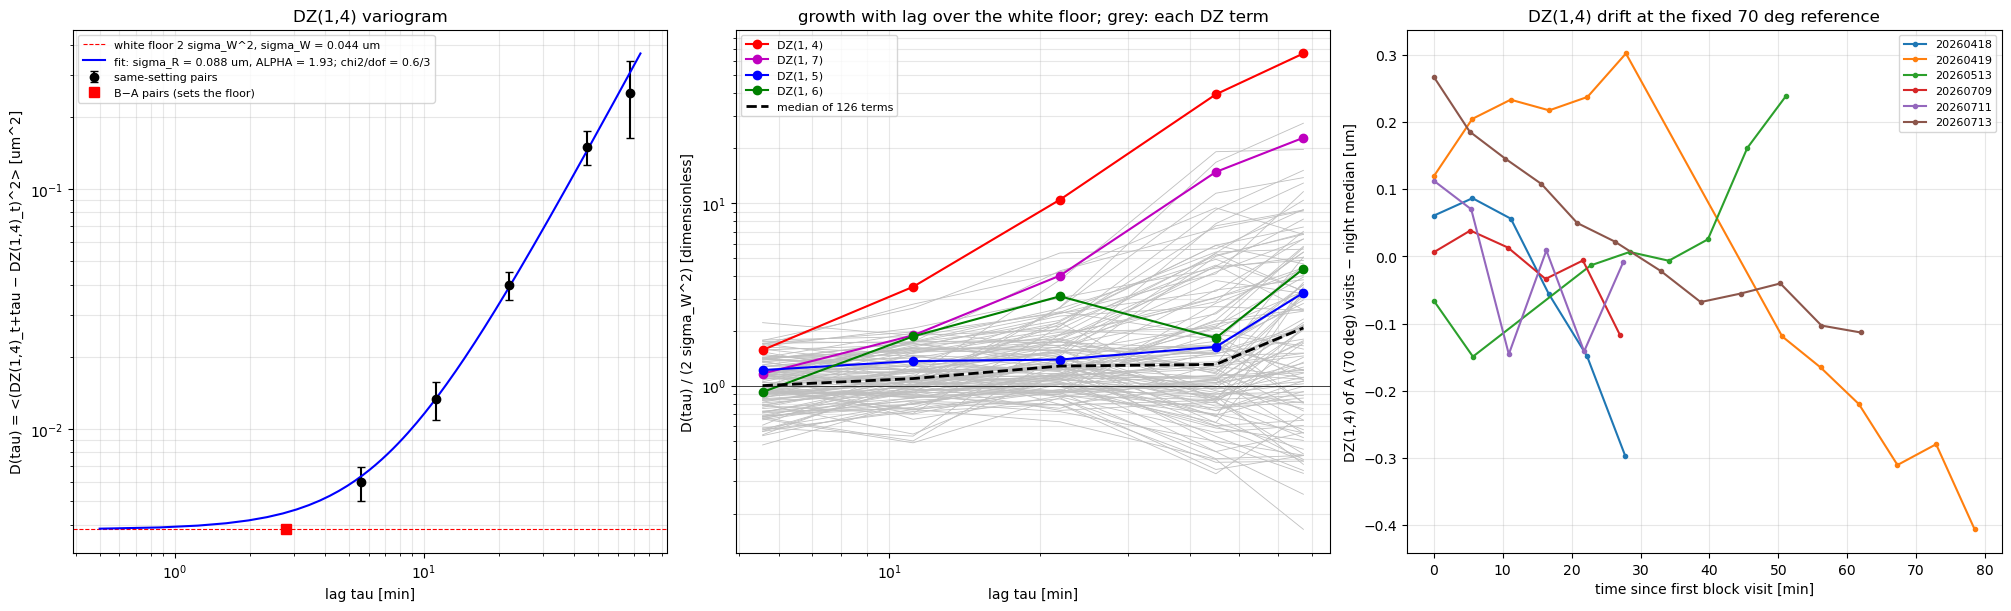

In [6]:
fig_vg, ax = plt.subplots(1, 3, figsize=(20, 6), layout='constrained')
tt_ = np.linspace(0.5, tb.max() * 1.1, 200)
ax[0].errorbar(tb, y, yerr=ey, fmt='ko', capsize=3, label='same-setting pairs')
ax[0].errorbar([pdf_pairs.lag_min.median()], [2 * SW_SD[i14] ** 2], fmt='rs', ms=7,
               label='B−A pairs (sets the floor)')
ax[0].axhline(2 * SW_SD[i14] ** 2, color='r', ls='--', lw=0.8,
              label=f'white floor 2 sigma_W^2, sigma_W = {SW_SD[i14]:.3f} um')
ax[0].plot(tt_, 2 * SW_SD[i14] ** 2 + SR14 ** 2 * (tt_ / T0_MIN) ** ALPHA14, 'b-',
           label=f'fit: sigma_R = {SR14:.3f} um, ALPHA = {ALPHA14:.2f}; chi2/dof = {chi2_r:.1f}/{dof_r}')
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('lag tau [min]'); ax[0].set_ylabel('D(tau) = <(DZ(1,4)_t+tau − DZ(1,4)_t)^2> [um^2]')
ax[0].set_title('DZ(1,4) variogram'); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, which='both')
for a in range(NT):
    ax[1].plot(tb, ratio[:, a], '-', color='0.75', lw=0.6)
for a, col in [(i14, 'r'), (KJ.index((1, 7)), 'm'), (KJ.index((1, 5)), 'b'), (KJ.index((1, 6)), 'g')]:
    ax[1].plot(tb, ratio[:, a], 'o-', color=col, lw=1.5, label=f'DZ{KJ[a]}')
ax[1].plot(tb, np.median(ratio, 1), 'k--', lw=2, label='median of 126 terms')
ax[1].axhline(1, color='k', lw=0.5)
ax[1].set_xscale('log'); ax[1].set_yscale('log')
ax[1].set_xlabel('lag tau [min]'); ax[1].set_ylabel('D(tau) / (2 sigma_W^2) [dimensionless]')
ax[1].set_title('growth with lag over the white floor; grey: each DZ term')
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, which='both')
for d in DAY_OBS:
    g = vv[(vv.night == d) & (vv.grp == 'A')].sort_values('t_min')
    if len(g):
        yy = W[g.row.to_numpy(), i14]
        ax[2].plot(g.t_min, yy - np.median(yy), 'o-', ms=3, color=plt.get_cmap('tab10')(DAY_OBS.index(d)), label=str(d))
ax[2].set_xlabel('time since first block visit [min]')
ax[2].set_ylabel('DZ(1,4) of A (70 deg) visits − night median [um]')
ax[2].set_title('DZ(1,4) drift at the fixed 70 deg reference'); ax[2].legend(fontsize=8); ax[2].grid(alpha=0.3)
plt.show()

<a id='mc'></a>
## A–B–A Δ, 22/12 recovery and Monte Carlo errors

Per (night, leg): ΔDZ is the median over B visits of the A–B–A differences. Then
ΔDOF = P22 ΔDZ, Δv = ΔDOF · T_V, the fit is PI ΔDZ and the residual ΔDZ − PI ΔDZ.
The MC draws are those of v2 (same seed); each goes through the same maps. The
error on every quantity is the sd over N_MC draws.

In [7]:
LW = np.linalg.cholesky(SIG_W + 1e-12 * np.trace(SIG_W) / NT * np.eye(NT))
rng = np.random.default_rng(SEED)
res = {}
t_s = time.time()
for L in legs:
    d, lab = L['night'], L['leg']
    v = leg_visits(d, lab); M = aba_matrix(v); Y = W[v.row.to_numpy()]
    dz = np.median(M @ Y, 0)
    u = (v.t_min.to_numpy() - v.t_min.min()) / T0_MIN
    Kt = 0.5 * (u[:, None] ** ALPHA14 + u[None, :] ** ALPHA14 - np.abs(u[:, None] - u[None, :]) ** ALPHA14)
    Lt = np.linalg.cholesky(Kt + 1e-9 * np.eye(len(u)))
    noise = rng.normal(size=(N_MC, len(v), NT)) @ LW.T
    noise[:, :, i14] += SR14 * rng.normal(size=(N_MC, len(v))) @ Lt.T
    dz_all = dz + np.median(np.einsum('bi,mik->mbk', M, noise), 1)
    dof_mc = dz_all @ P22.T; fit_mc = dz_all @ PI.T
    r = dict(dz=dz, dz_err=dz_all.std(0, ddof=1), dof=P22 @ dz, dof_mc=dof_mc,
             dof_err=dof_mc.std(0, ddof=1), fit=PI @ dz, fit_err=fit_mc.std(0, ddof=1))
    r['resid'] = dz - r['fit']; r['resid_err'] = (dz_all - fit_mc).std(0, ddof=1)
    r['v'] = r['dof'] @ T_V; r['v_err'] = (dof_mc @ T_V).std(0, ddof=1)
    c14_mc = dof_mc * F22[i14]
    r['c14'] = F22[i14] * r['dof']; r['c14_err'] = c14_mc.std(0, ddof=1)
    res[(d, lab)] = r
print(f'MC: {N_MC} draws × {len(legs)} legs in {time.time() - t_s:.0f} s')

# DOF -> aos_state v-modes -> DOF: how much of the 22/12 ΔDOF the OFC basis keeps
wn = svd.normalization_weights
lost = []
for r in res.values():
    full = np.zeros(50); full[DOF22] = r['dof']
    back = np.asarray(se22.get_dofs_from_vmodes(np.asarray(se22.get_vmodes_from_dofs(full))[:NK])).ravel()
    back = back[DOF22] if back.size == 50 else back
    lost.append(np.sum(((r['dof'] - back) / wn) ** 2) / np.sum((r['dof'] / wn) ** 2))
LOST = np.array(lost)
print(f'normalized-DOF power lost going 22/12 ΔDOF -> aos_state 12 v-modes -> DOF: '
      f'{LOST.min():.3f} to {LOST.max():.3f} (dimensionless; lost over total, per leg)')

MC: 1000 draws × 7 legs in 0 s
normalized-DOF power lost going 22/12 ΔDOF -> aos_state 12 v-modes -> DOF: 0.013 to 0.028 (dimensionless; lost over total, per leg)


<a id='resid'></a>
## How well 22/12 represents the ΔDZ

Per leg: the ΔDZ power (sum over the 126 terms of ΔDZ², µm²), the fraction of it
the fit leaves, and the residual chi2/dof with the diagonal MC errors (dof = 126 − 12
for 22/12; the correlations between terms are ignored). The RBR 50/50 numbers come
from the v3 run.

In [8]:
rbr_r = pd.read_csv(run.path.parent / RBR_RUN / 'bounce_aba_dz_residual.csv')
rbr_s = pd.read_csv(run.path.parent / RBR_RUN / 'bounce_aba_optical_state.csv')
names = [f'DZ({k},{j})' for k, j in KJ]
for L in legs:
    r = res[(L['night'], L['leg'])]
    g = rbr_r[(rbr_r.night == L['night']) & (rbr_r.leg == L['leg'])].set_index('name').loc[names]
    r['rbr_resid'] = g.resid.to_numpy(); r['rbr_resid_err'] = g.resid_err.to_numpy()
    s = rbr_s[(rbr_s.night == L['night']) & (rbr_s.leg == L['leg']) & (rbr_s.kind == 'DOF')]
    s = s.set_index('name').loc[LAB]
    r['rbr_dof'] = s.delta.to_numpy(); r['rbr_dof_err'] = s.err.to_numpy()
    assert np.allclose(g.delta.to_numpy(), r['dz'], atol=1e-9), 'v3 ΔDZ differs from this ΔDZ'
rows = []
for L in legs:
    r = res[(L['night'], L['leg'])]
    p = (r['dz'] ** 2).sum()
    rows.append({'night': L['night'], 'leg': L['leg'], 'dDZ_power_um2': p,
                 'left_22_12': (r['resid'] ** 2).sum() / p,
                 'left_rbr_50_50': (r['rbr_resid'] ** 2).sum() / p,
                 'chi2_dDZ_126': ((r['dz'] / r['dz_err']) ** 2).sum(),
                 'chi2_resid_22_12_114': ((r['resid'] / r['resid_err']) ** 2).sum(),
                 'dDZ14_um': r['dz'][i14], 'resid14_22_12_um': r['resid'][i14],
                 'resid14_err_um': r['resid_err'][i14],
                 'max_dof_over_range': np.max(np.abs(r['dof']) / RANGE)})
summ = pd.DataFrame(rows)
print('left_* = residual power over ΔDZ power, sum over 126 terms (dimensionless); '
      'chi2 with diagonal MC errors, dof in the column name; max |ΔDOF| / range (dimensionless)')
summ.round(4)

left_* = residual power over ΔDZ power, sum over 126 terms (dimensionless); chi2 with diagonal MC errors, dof in the column name; max |ΔDOF| / range (dimensionless)


,night,leg,dDZ_power_um2,left_22_12,left_rbr_50_50,chi2_dDZ_126,chi2_resid_22_12_114,dDZ14_um,resid14_22_12_um,resid14_err_um,max_dof_over_range
0,20260418,Elev=40,0.1219,0.1075,0.0503,1674.5918,1294.2843,-0.0682,-0.0003,0.0001,0.3766
1,20260419,Elev=40,0.2274,0.0564,0.0185,3091.1830,1985.5338,-0.1219,-0.0002,0.0001,0.2249
2,20260513,Elev=40,0.2102,0.0460,0.0179,2899.5917,1975.6023,0.0086,-0.0001,0.0001,0.3295
3,20260709,Elev=60,0.0644,0.0981,0.0218,300.2547,201.8816,0.0703,0.0002,0.0001,0.1229
4,20260711,Elev=50,0.2585,0.0462,0.0178,1424.7084,991.1854,0.1751,-0.0001,0.0001,0.5097
5,20260713,Elev=30,0.3036,0.0453,0.0192,2967.0996,2147.6275,0.3660,-0.0000,0.0001,0.2629
6,20260713,Elev=75,0.0284,0.0296,0.0113,226.9625,161.1708,0.0146,-0.0000,0.0001,0.0555


<a id='plots'></a>
## Plots: v-modes, DOF, residuals and DZ vs elevation

One point per (night, leg), with its MC error. The three 40 deg nights are offset
by ±0.6 deg in x. Each panel title gives chi2/dof of the three 40 deg nights about
their weighted mean (dof = 2). Grey open squares are RBR 50/50 (v3).

In [9]:
ncol = {n: plt.get_cmap('tab10')(i % 10) for i, n in enumerate(sorted({L['night'] for L in legs}))}
xoff = {n: o for n, o in zip([20260418, 20260419, 20260513], [-0.6, 0.0, 0.6])}


def chi2_40(vals, errs, bvals):
    m = bvals == 40.0
    x, e = vals[m], errs[m]
    if m.sum() < 2 or not np.all(e > 0):
        return np.nan
    w = 1 / e ** 2; mu = np.sum(w * x) / np.sum(w)
    return float(np.sum(w * (x - mu) ** 2))


bvals = np.array([L['b_value_deg'] for L in legs])


def panel(a_, getv, gete, title, ylabel):
    vals = np.array([getv(res[(L['night'], L['leg'])]) for L in legs])
    errs = np.array([gete(res[(L['night'], L['leg'])]) for L in legs])
    for L, y, e in zip(legs, vals, errs):
        a_.errorbar(L['b_value_deg'] + xoff.get(L['night'], 0.0), y, yerr=e, fmt='o', ms=4,
                    color=ncol[L['night']], mec='k', mew=0.4, capsize=2)
    a_.axhline(0, color='gray', lw=0.5); a_.grid(alpha=0.3)
    c2 = chi2_40(vals, errs, bvals)
    a_.set_title(f'{title}   40 deg chi2/dof = {c2:.1f}/2', fontsize=8)
    a_.set_ylabel(ylabel, fontsize=7); a_.tick_params(labelsize=7)
    a_.set_xlim(25, 80)


def legend_fig(fig):
    h = [plt.Line2D([], [], marker='o', ls='', color=ncol[n], mec='k', label=str(n)) for n in ncol]
    fig.legend(handles=h, loc='outside lower center', ncols=len(ncol), fontsize=8, title='day_obs')


fraction of ΔDZ power left, all terms and legs: 22/12 = 0.056, RBR 50/50 = 0.022 (dimensionless; residual^2 over ΔDZ^2)
largest 22/12 residual chi2/dof (dof = 7): [('DZ(6, 19)', np.float64(1583.6)), ('DZ(5, 16)', np.float64(726.3)), ('DZ(3, 24)', np.float64(581.1)), ('DZ(3, 14)', np.float64(525.8)), ('DZ(1, 17)', np.float64(497.3)), ('DZ(3, 22)', np.float64(401.9)), ('DZ(1, 7)', np.float64(357.7)), ('DZ(3, 26)', np.float64(340.0)), ('DZ(4, 17)', np.float64(310.7)), ('DZ(6, 9)', np.float64(286.8))]


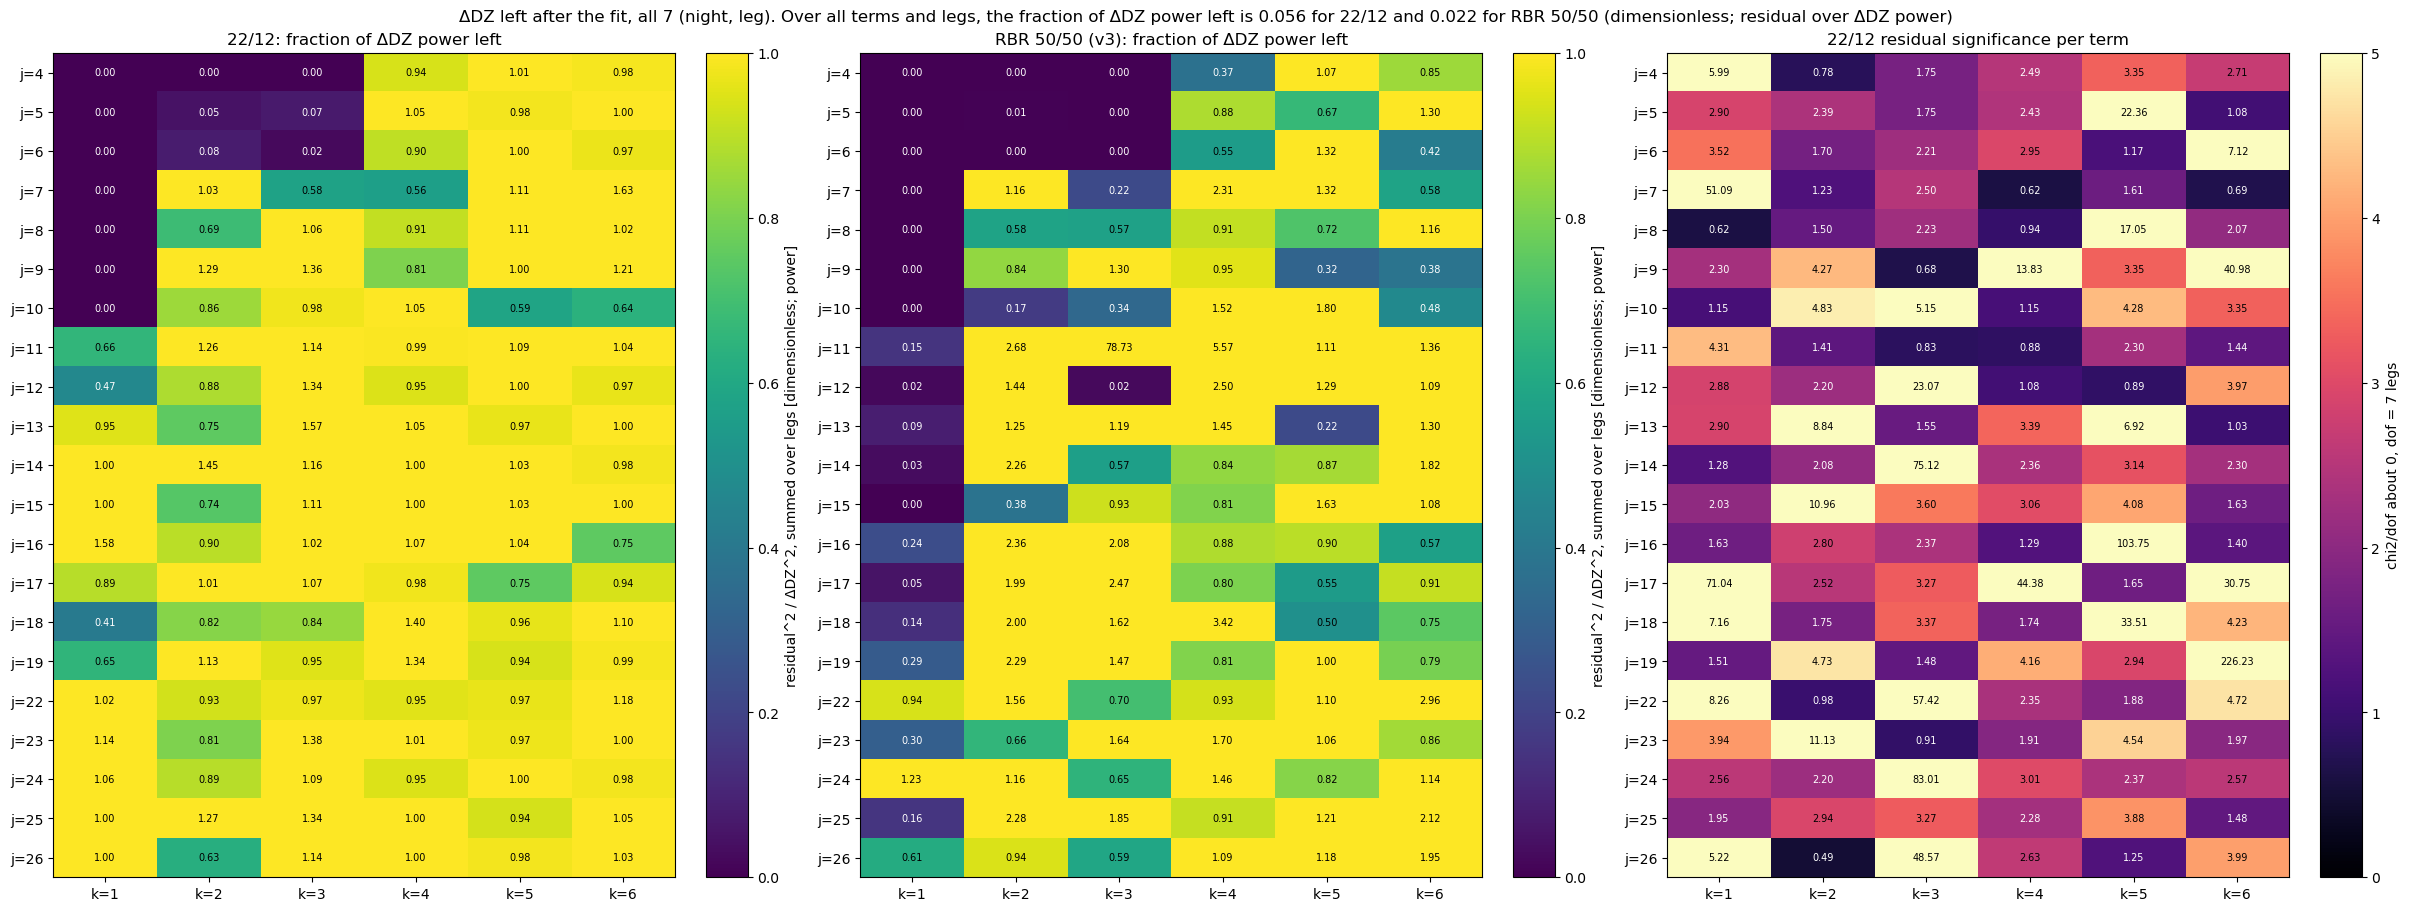

In [10]:
def overlay(a_, getv, gete, **kw):
    for L in legs:
        r = res[(L['night'], L['leg'])]
        a_.errorbar(L['b_value_deg'] + xoff.get(L['night'], 0.0) + 0.3, getv(r), yerr=gete(r),
                    fmt=kw.get('fmt', 's'), ms=4, mfc='none', color=kw.get('color', '0.45'),
                    capsize=1.5, lw=0.8)


ks = sorted({k for k, _ in KJ})
grid = lambda q: np.array([[q[KJ.index((k, j))] for k in ks] for j in iZs])
rs = np.array([res[(L['night'], L['leg'])]['resid'] for L in legs])
re_ = np.array([res[(L['night'], L['leg'])]['resid_err'] for L in legs])
rr = np.array([res[(L['night'], L['leg'])]['rbr_resid'] for L in legs])
dzs = np.array([res[(L['night'], L['leg'])]['dz'] for L in legs])
pf22 = (rs ** 2).sum(0) / (dzs ** 2).sum(0); pfr = (rr ** 2).sum(0) / (dzs ** 2).sum(0)
c2r = ((rs / re_) ** 2).sum(0)
fig_rsum, ax = plt.subplots(1, 3, figsize=(24, 9), layout='constrained')
for a_, q, lab, kw in [(ax[0], pf22, 'residual^2 / ΔDZ^2, summed over legs [dimensionless; power]',
                        dict(vmin=0, vmax=1, cmap='viridis')),
                       (ax[1], pfr, 'residual^2 / ΔDZ^2, summed over legs [dimensionless; power]',
                        dict(vmin=0, vmax=1, cmap='viridis')),
                       (ax[2], c2r / len(legs), f'chi2/dof about 0, dof = {len(legs)} legs',
                        dict(vmin=0, vmax=5, cmap='magma'))]:
    im = a_.imshow(grid(q), aspect='auto', **kw)
    a_.set_xticks(range(len(ks)), [f'k={k}' for k in ks]); a_.set_yticks(range(len(iZs)), [f'j={j}' for j in iZs])
    for (yi, xi), val in np.ndenumerate(grid(q)):
        a_.text(xi, yi, f'{val:.2f}', ha='center', va='center', fontsize=7,
                color='w' if val < 0.5 * kw['vmax'] else 'k')
    fig_rsum.colorbar(im, ax=a_, label=lab)
ax[0].set_title('22/12: fraction of ΔDZ power left')
ax[1].set_title('RBR 50/50 (v3): fraction of ΔDZ power left')
ax[2].set_title('22/12 residual significance per term')
tot22 = (rs ** 2).sum() / (dzs ** 2).sum(); totr = (rr ** 2).sum() / (dzs ** 2).sum()
fig_rsum.suptitle(f'ΔDZ left after the fit, all {len(legs)} (night, leg). Over all terms and legs, the '
                  f'fraction of ΔDZ power left is {tot22:.3f} for 22/12 and {totr:.3f} for RBR 50/50 '
                  '(dimensionless; residual over ΔDZ power)')
print(f'fraction of ΔDZ power left, all terms and legs: 22/12 = {tot22:.3f}, RBR 50/50 = {totr:.3f} '
      '(dimensionless; residual^2 over ΔDZ^2)')
order = np.argsort(-c2r)[:10]
print('largest 22/12 residual chi2/dof (dof = 7):', [(f'DZ{KJ[a]}', round(c2r[a], 1)) for a in order])
plt.show()

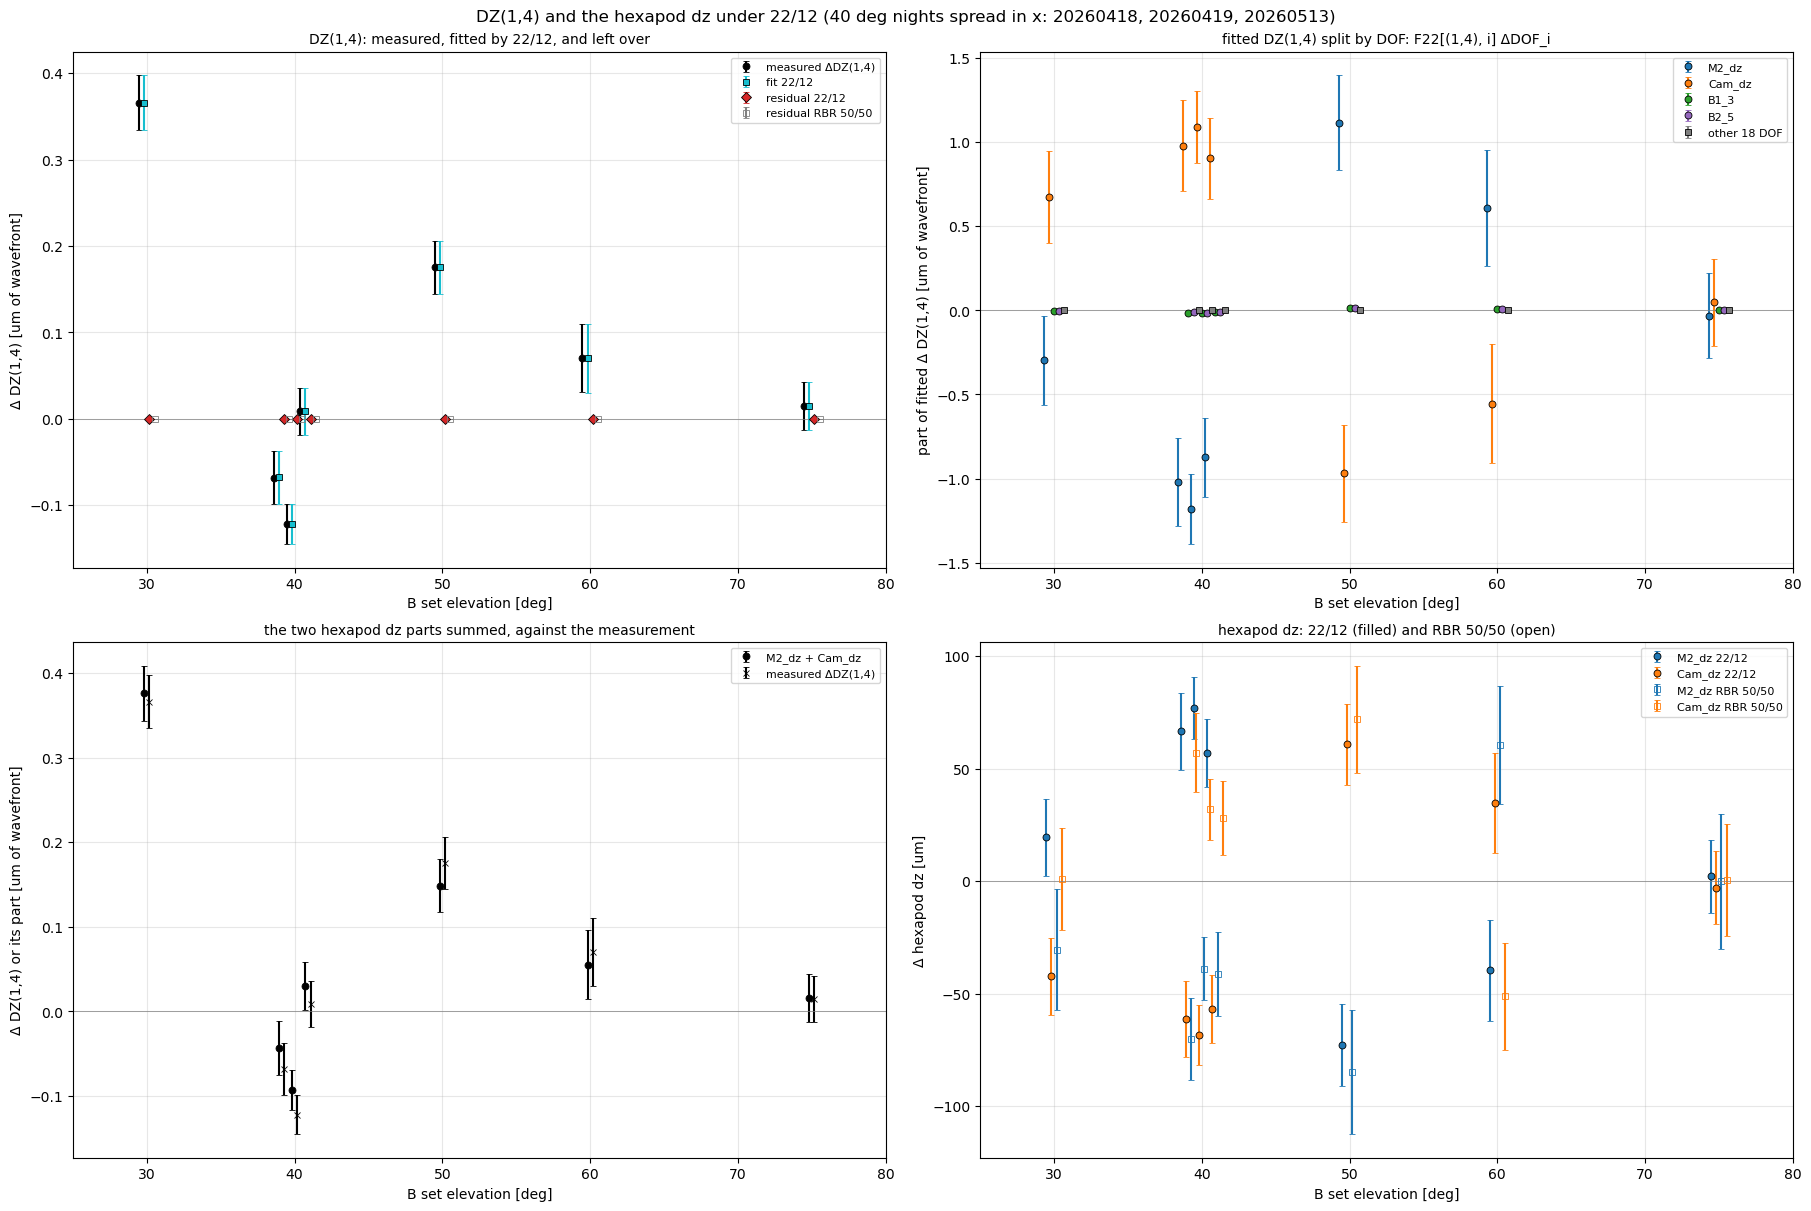

In [11]:
FOCUS = [('M2_dz', 0), ('Cam_dz', 5), ('B1_3', LAB.index('B1_3')), ('B2_5', LAB.index('B2_5'))]
oth = np.ones(ND, bool); oth[[i for _, i in FOCUS]] = False
for r in res.values():
    c14_mc = r['dof_mc'] * F22[i14]
    r['c14_oth'] = r['c14'][oth].sum(); r['c14_oth_err'] = c14_mc[:, oth].sum(1).std(ddof=1)
    r['c14_hex'] = r['c14'][[0, 5]].sum(); r['c14_hex_err'] = c14_mc[:, [0, 5]].sum(1).std(ddof=1)
S_COL = {'M2_dz': 'tab:blue', 'Cam_dz': 'tab:orange', 'B1_3': 'tab:green', 'B2_5': 'tab:purple',
         f'other {ND - 4} DOF': '0.5', 'M2_dz + Cam_dz': 'k', 'measured ΔDZ(1,4)': 'k',
         'fit 22/12': 'tab:cyan', 'residual 22/12': 'tab:red', 'residual RBR 50/50': '0.5',
         'M2_dz 22/12': 'tab:blue', 'Cam_dz 22/12': 'tab:orange',
         'M2_dz RBR 50/50': 'tab:blue', 'Cam_dz RBR 50/50': 'tab:orange'}


def series(a_, items, title):
    n = len(items)
    for si, (lab, getv, gete, mk) in enumerate(items):
        for L in legs:
            r = res[(L['night'], L['leg'])]
            x = L['b_value_deg'] + xoff.get(L['night'], 0.0) * 1.5 + (si - (n - 1) / 2) * 0.35
            a_.errorbar(x, getv(r), yerr=gete(r), fmt=mk, ms=5, color=S_COL.get(lab, 'k'),
                        mfc='none' if 'RBR' in lab else None, mec=S_COL.get(lab, 'k') if 'RBR' in lab else 'k',
                        mew=0.6, capsize=2, label=lab if L is legs[0] else None)
    a_.axhline(0, color='gray', lw=0.5); a_.grid(alpha=0.3); a_.set_xlim(25, 80)
    a_.set_xlabel('B set elevation [deg]'); a_.set_title(title, fontsize=10); a_.legend(fontsize=8)


fig_focus, ax = plt.subplots(2, 2, figsize=(18, 12), layout='constrained')
series(ax[0, 0], [('measured ΔDZ(1,4)', lambda r: r['dz'][i14], lambda r: r['dz_err'][i14], 'o'),
                  ('fit 22/12', lambda r: r['fit'][i14], lambda r: r['fit_err'][i14], 's'),
                  ('residual 22/12', lambda r: r['resid'][i14], lambda r: r['resid_err'][i14], 'D'),
                  ('residual RBR 50/50', lambda r: r['rbr_resid'][i14], lambda r: r['rbr_resid_err'][i14], 's')],
       'DZ(1,4): measured, fitted by 22/12, and left over')
ax[0, 0].set_ylabel('Δ DZ(1,4) [um of wavefront]')
series(ax[0, 1], [(n, (lambda r, i=i: r['c14'][i]), (lambda r, i=i: r['c14_err'][i]), 'o') for n, i in FOCUS]
       + [(f'other {ND - 4} DOF', lambda r: r['c14_oth'], lambda r: r['c14_oth_err'], 's')],
       'fitted DZ(1,4) split by DOF: F22[(1,4), i] ΔDOF_i')
ax[0, 1].set_ylabel('part of fitted Δ DZ(1,4) [um of wavefront]')
series(ax[1, 0], [('M2_dz + Cam_dz', lambda r: r['c14_hex'], lambda r: r['c14_hex_err'], 'o'),
                  ('measured ΔDZ(1,4)', lambda r: r['dz'][i14], lambda r: r['dz_err'][i14], 'x')],
       'the two hexapod dz parts summed, against the measurement')
ax[1, 0].set_ylabel('Δ DZ(1,4) or its part [um of wavefront]')
series(ax[1, 1], [('M2_dz 22/12', lambda r: r['dof'][0], lambda r: r['dof_err'][0], 'o'),
                  ('Cam_dz 22/12', lambda r: r['dof'][5], lambda r: r['dof_err'][5], 'o'),
                  ('M2_dz RBR 50/50', lambda r: r['rbr_dof'][0], lambda r: r['rbr_dof_err'][0], 's'),
                  ('Cam_dz RBR 50/50', lambda r: r['rbr_dof'][5], lambda r: r['rbr_dof_err'][5], 's')],
       'hexapod dz: 22/12 (filled) and RBR 50/50 (open)')
ax[1, 1].set_ylabel('Δ hexapod dz [um]')
fig_focus.suptitle('DZ(1,4) and the hexapod dz under 22/12 '
                   '(40 deg nights spread in x: 20260418, 20260419, 20260513)')
plt.show()

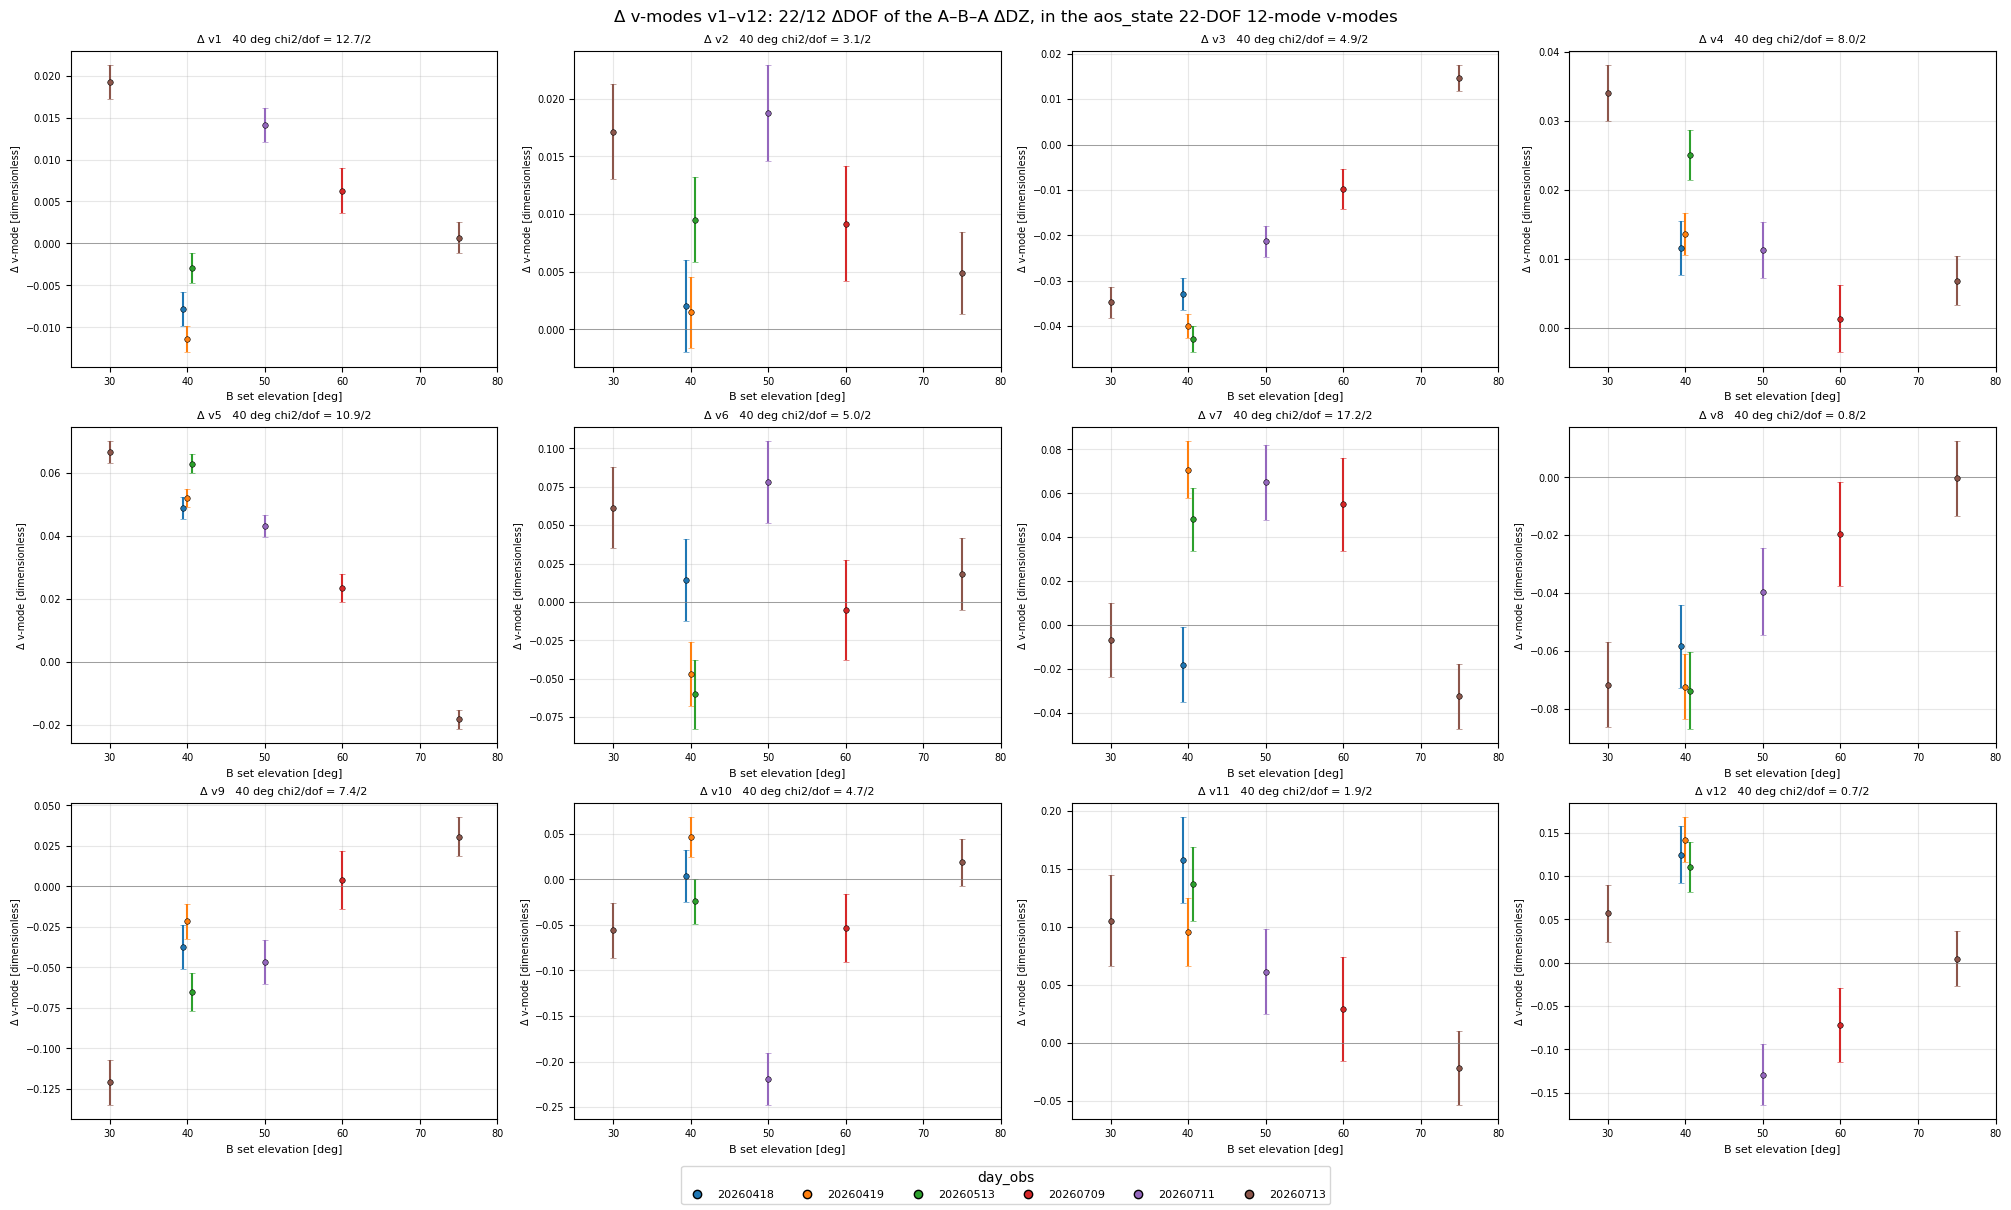

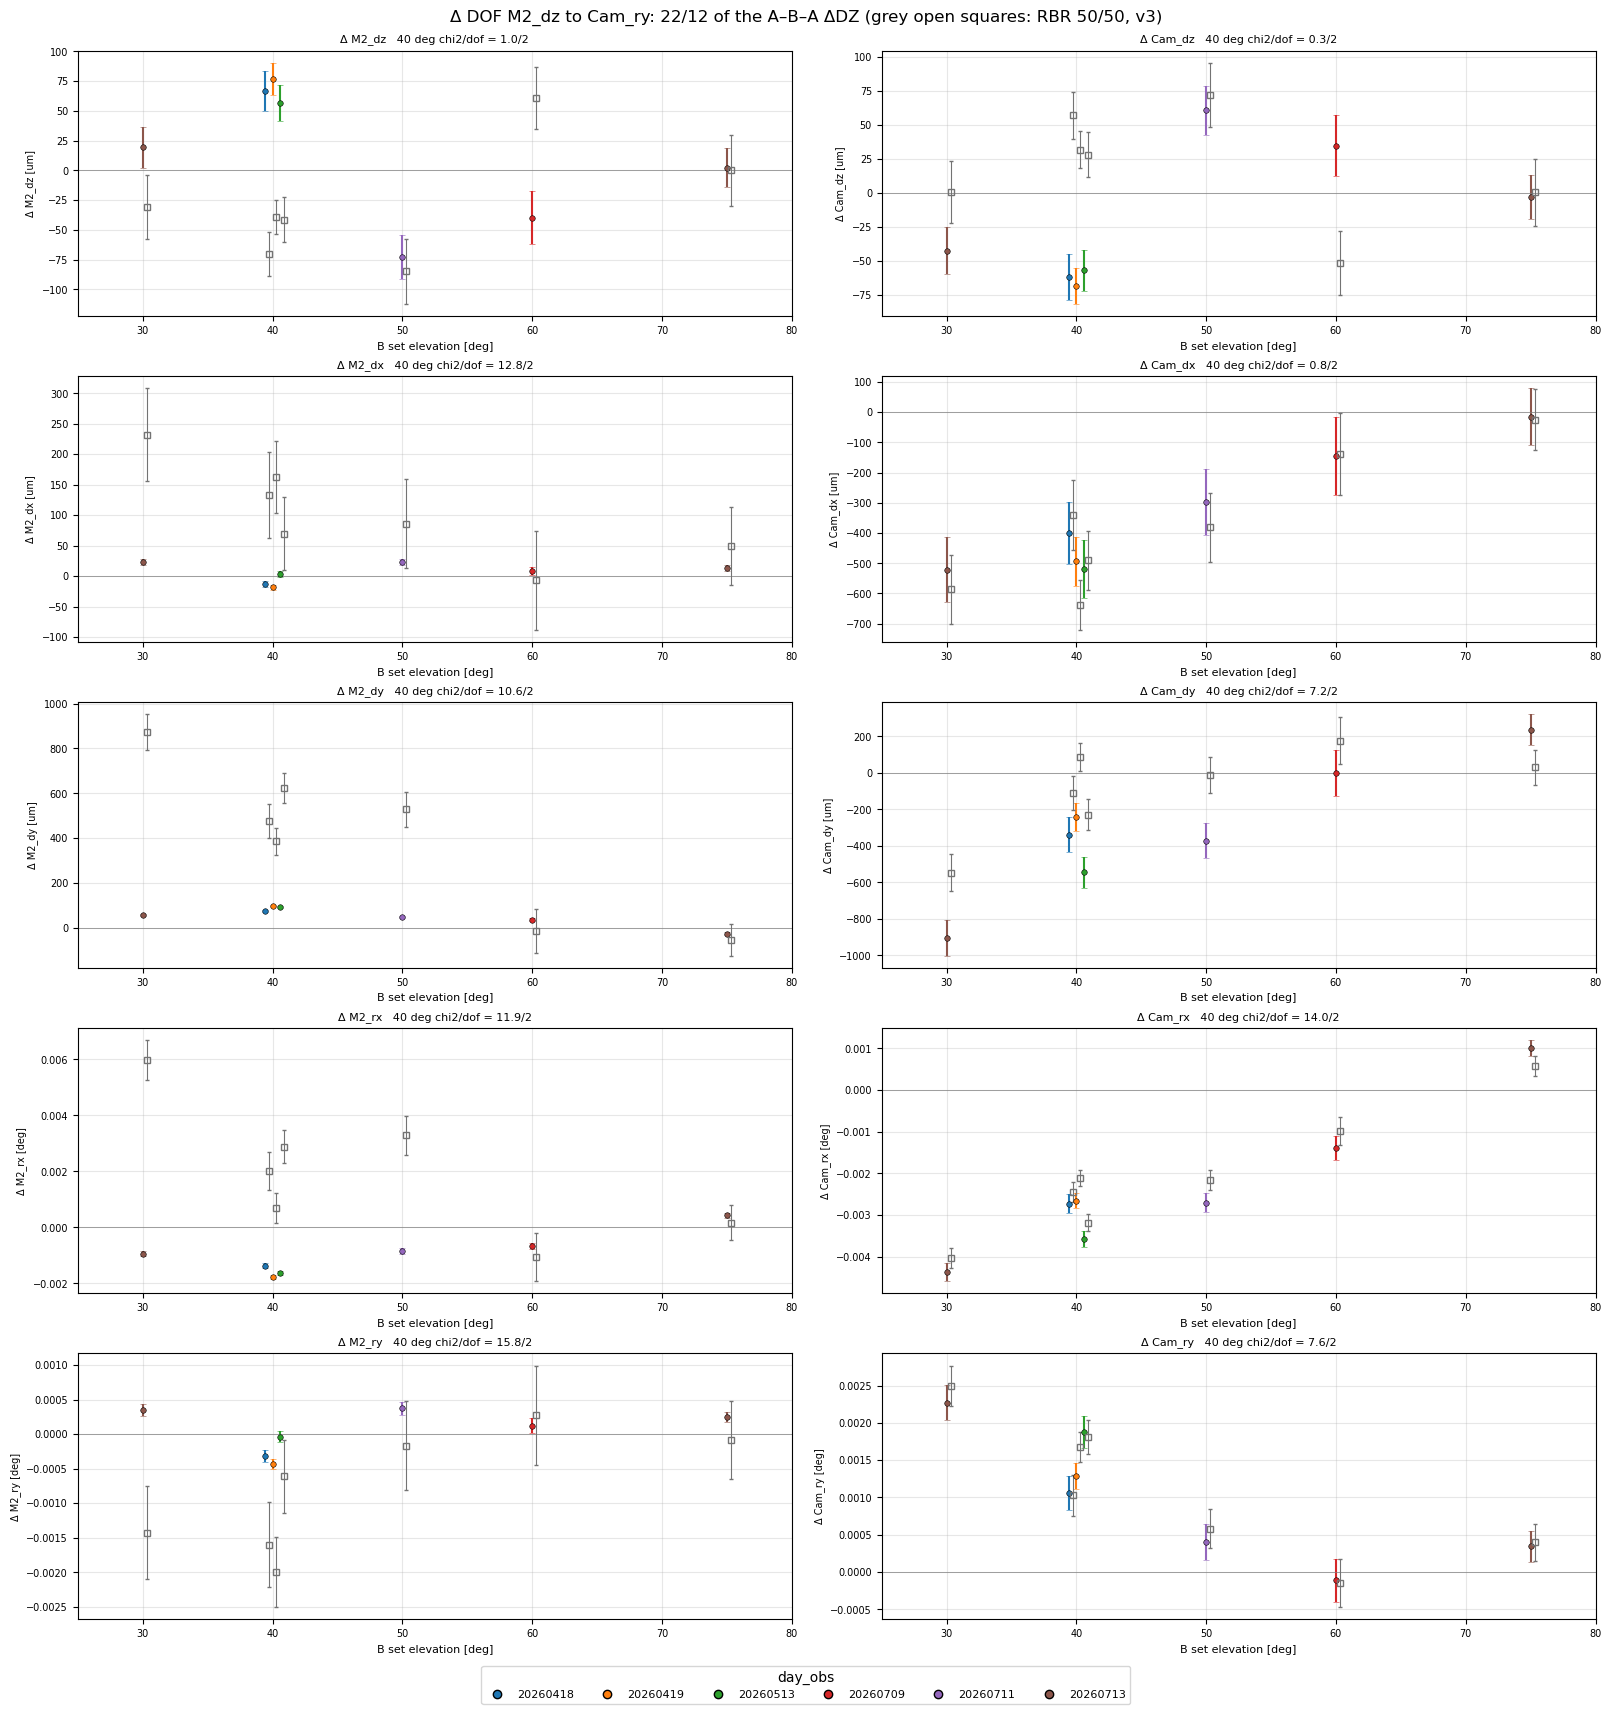

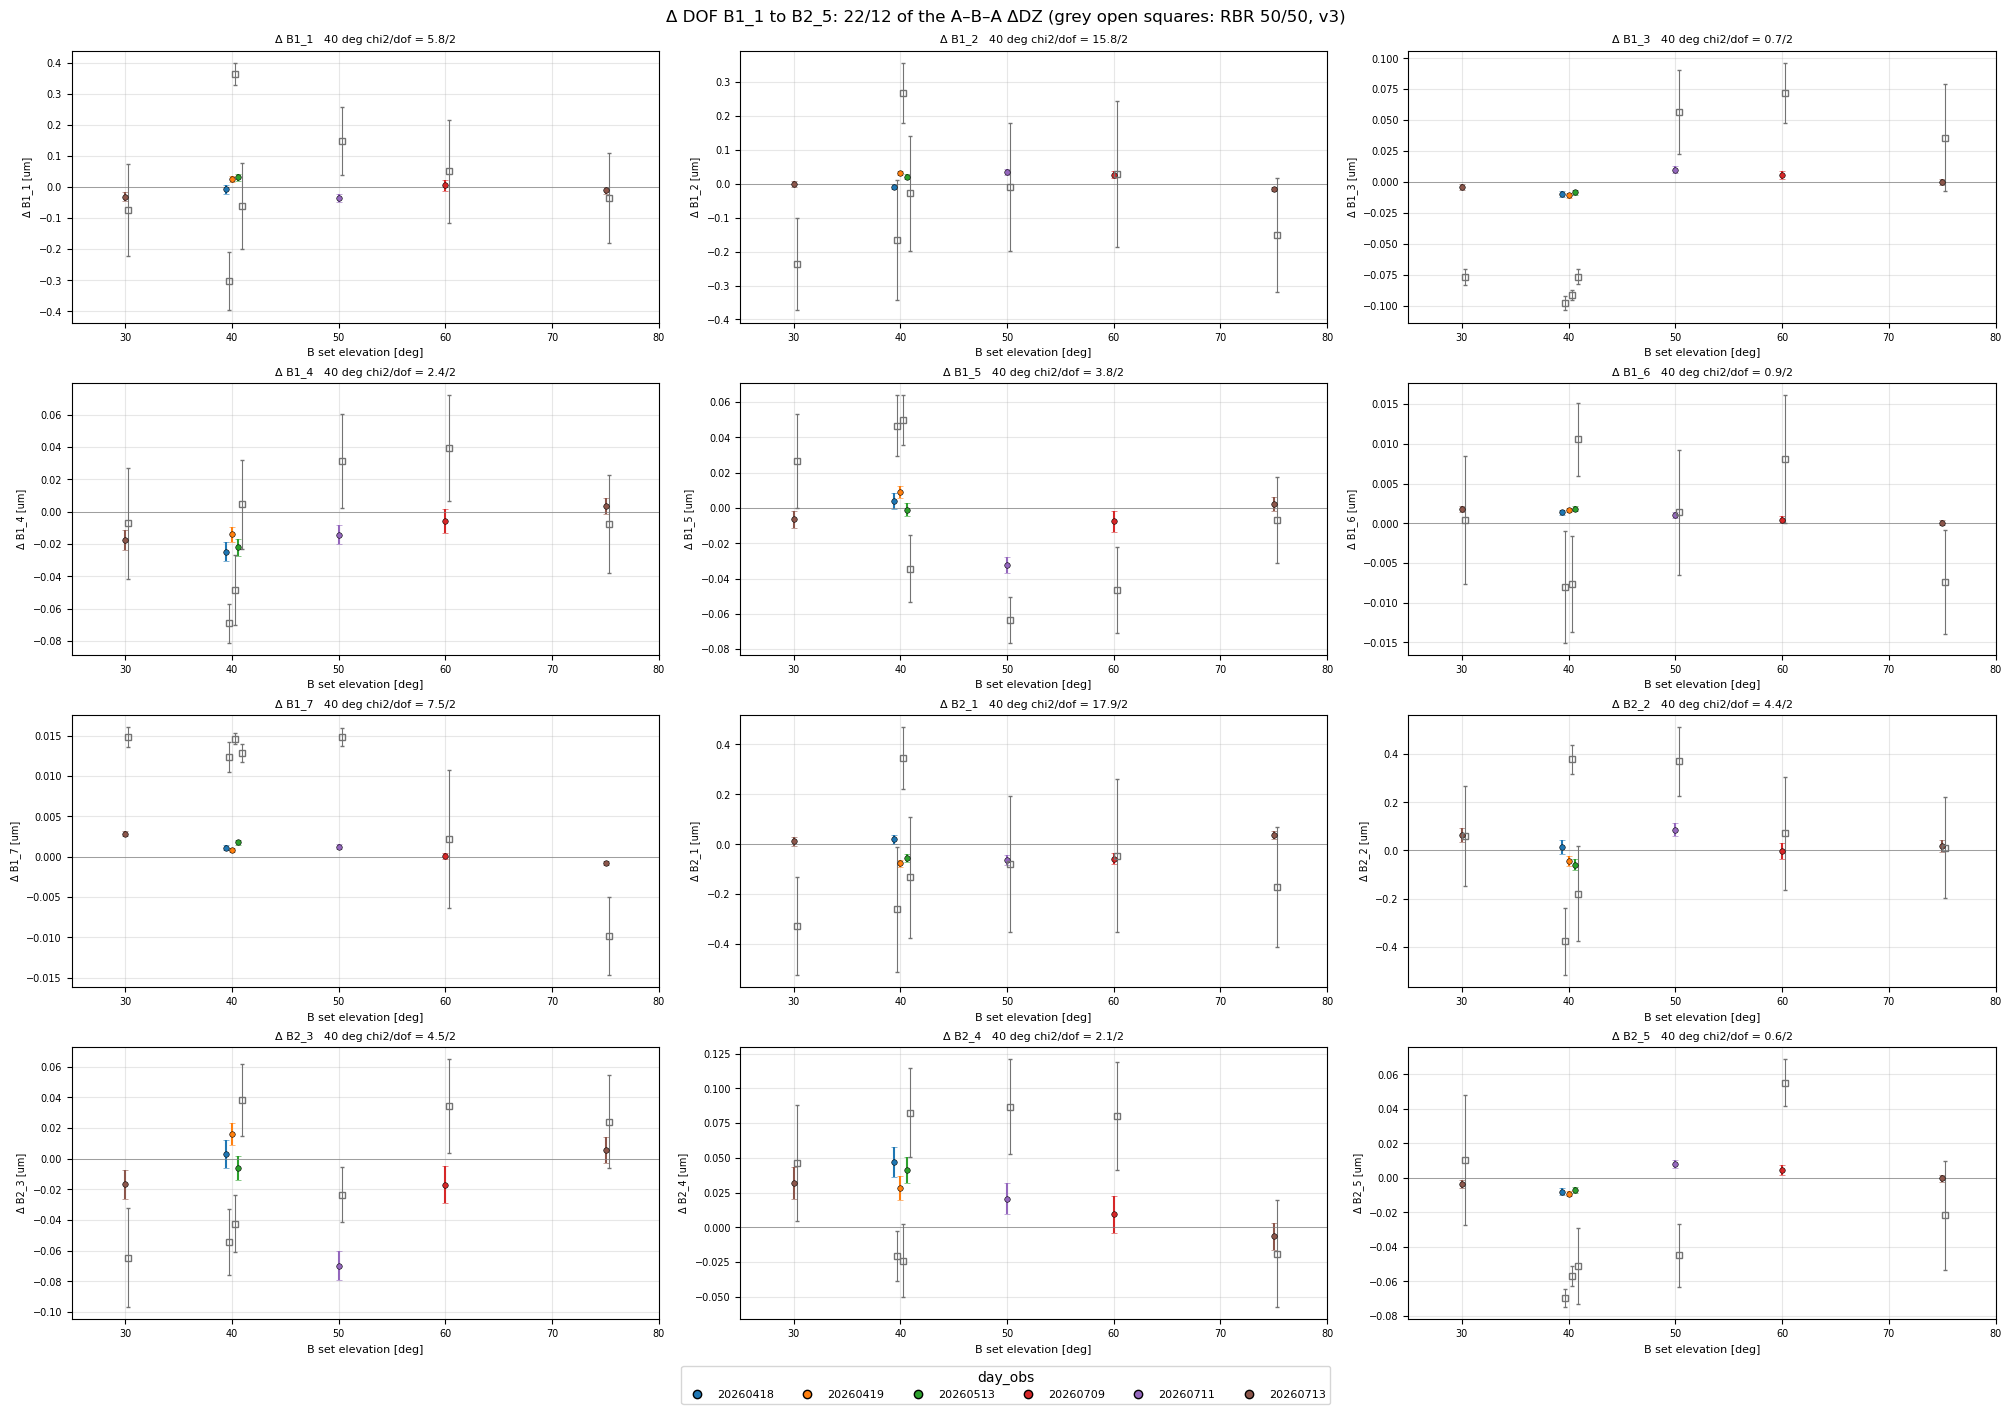

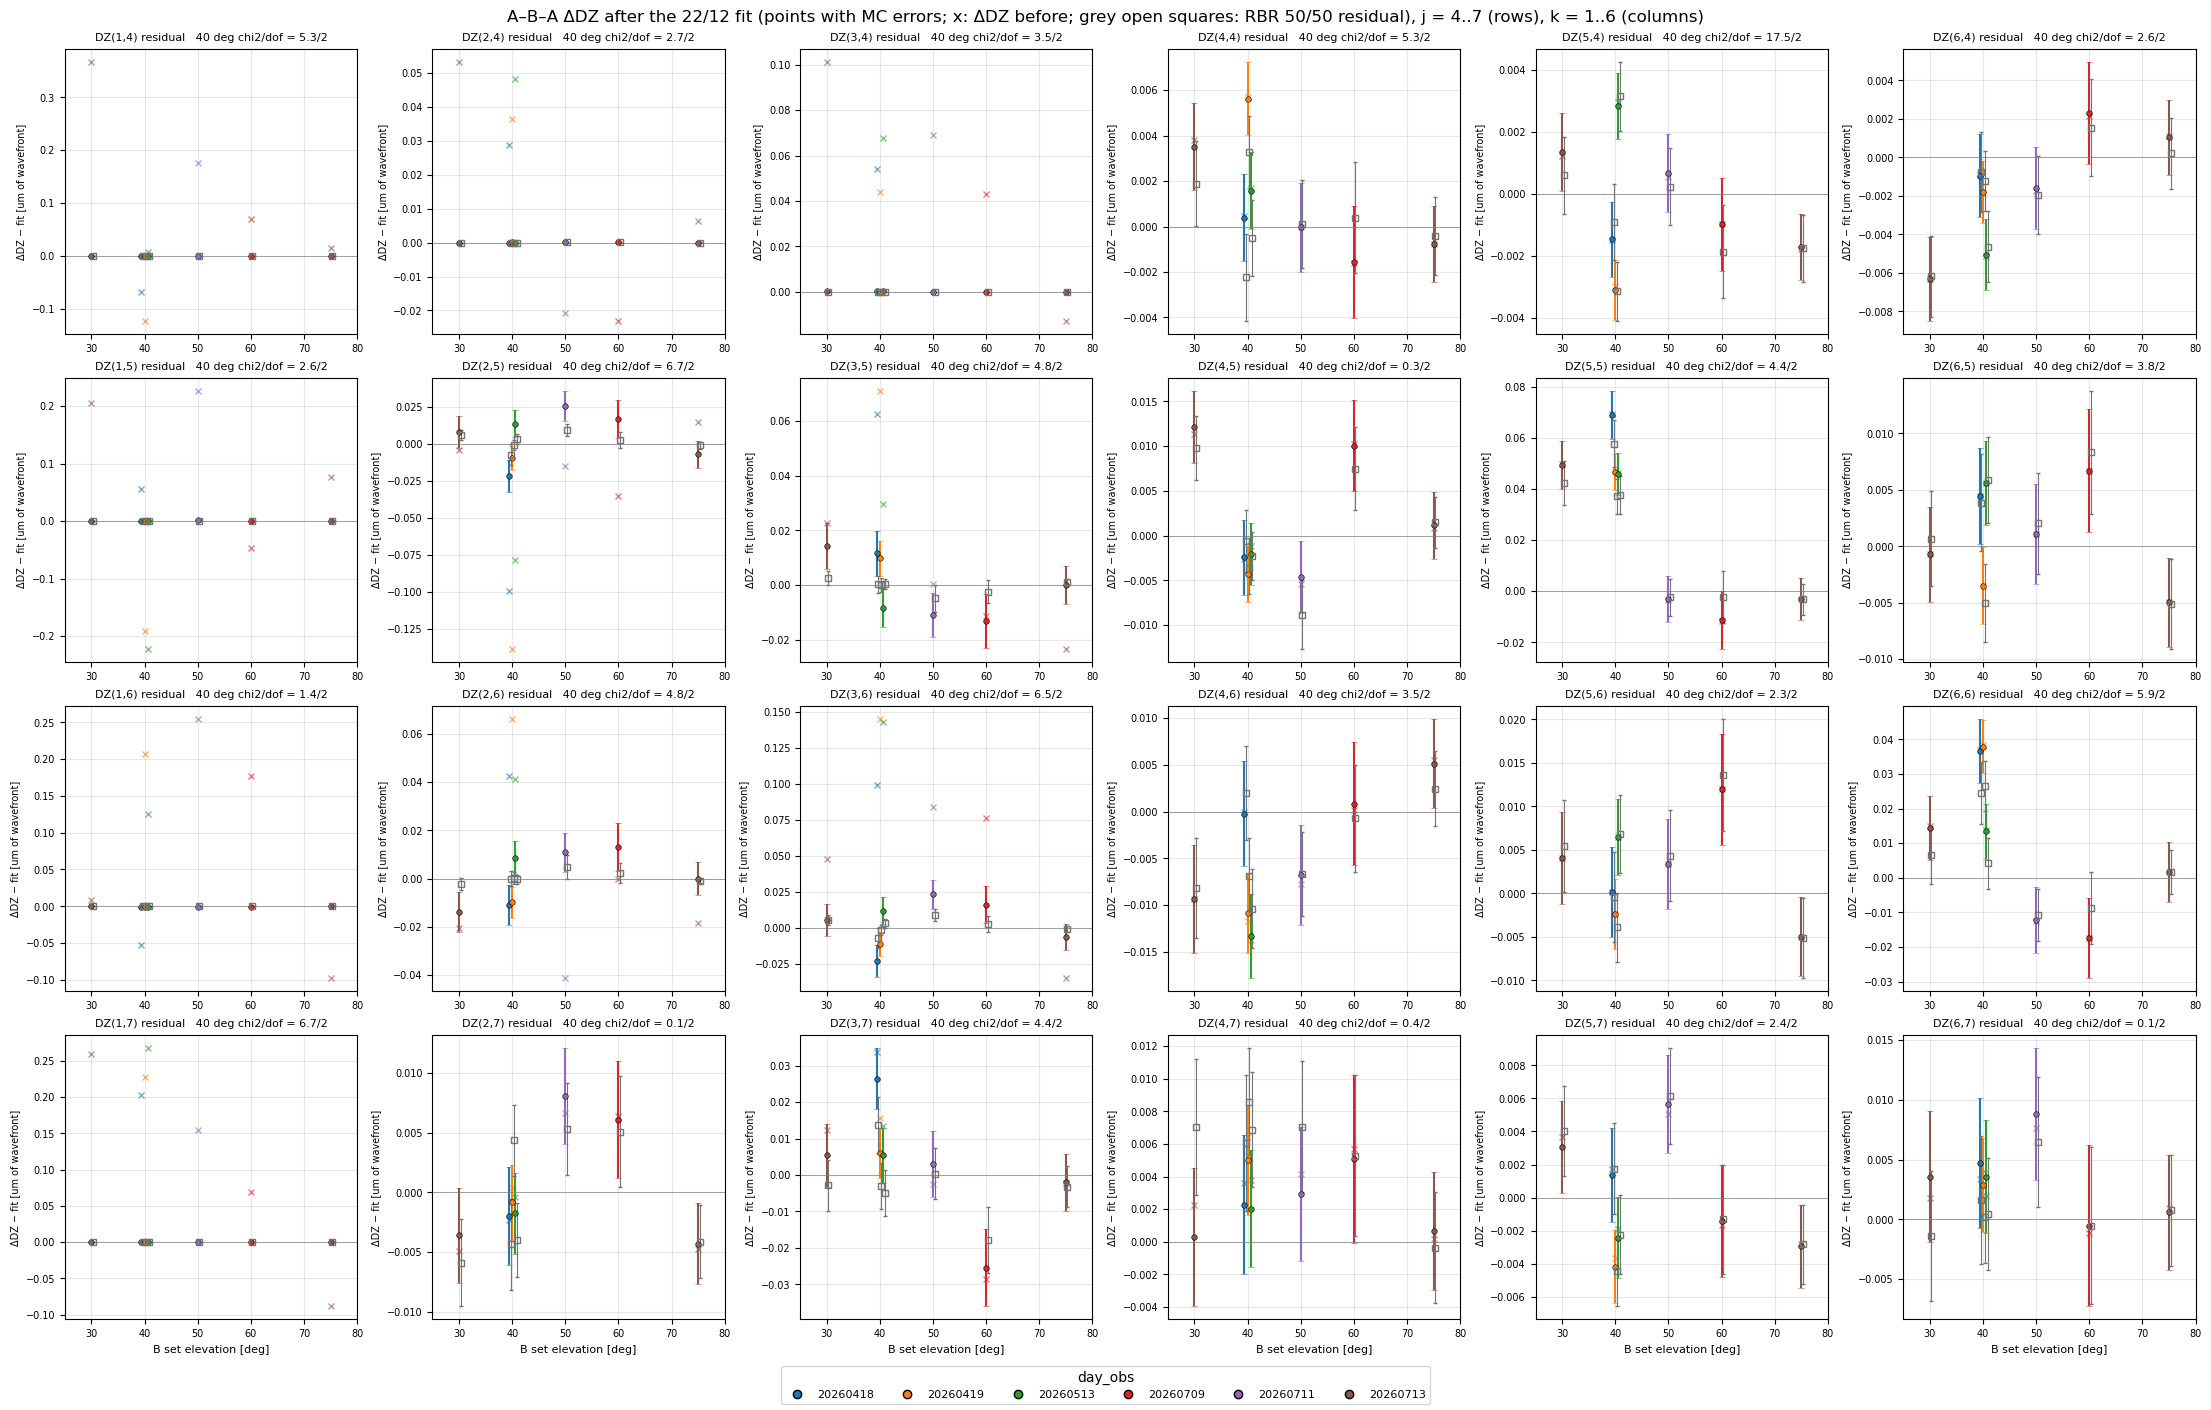

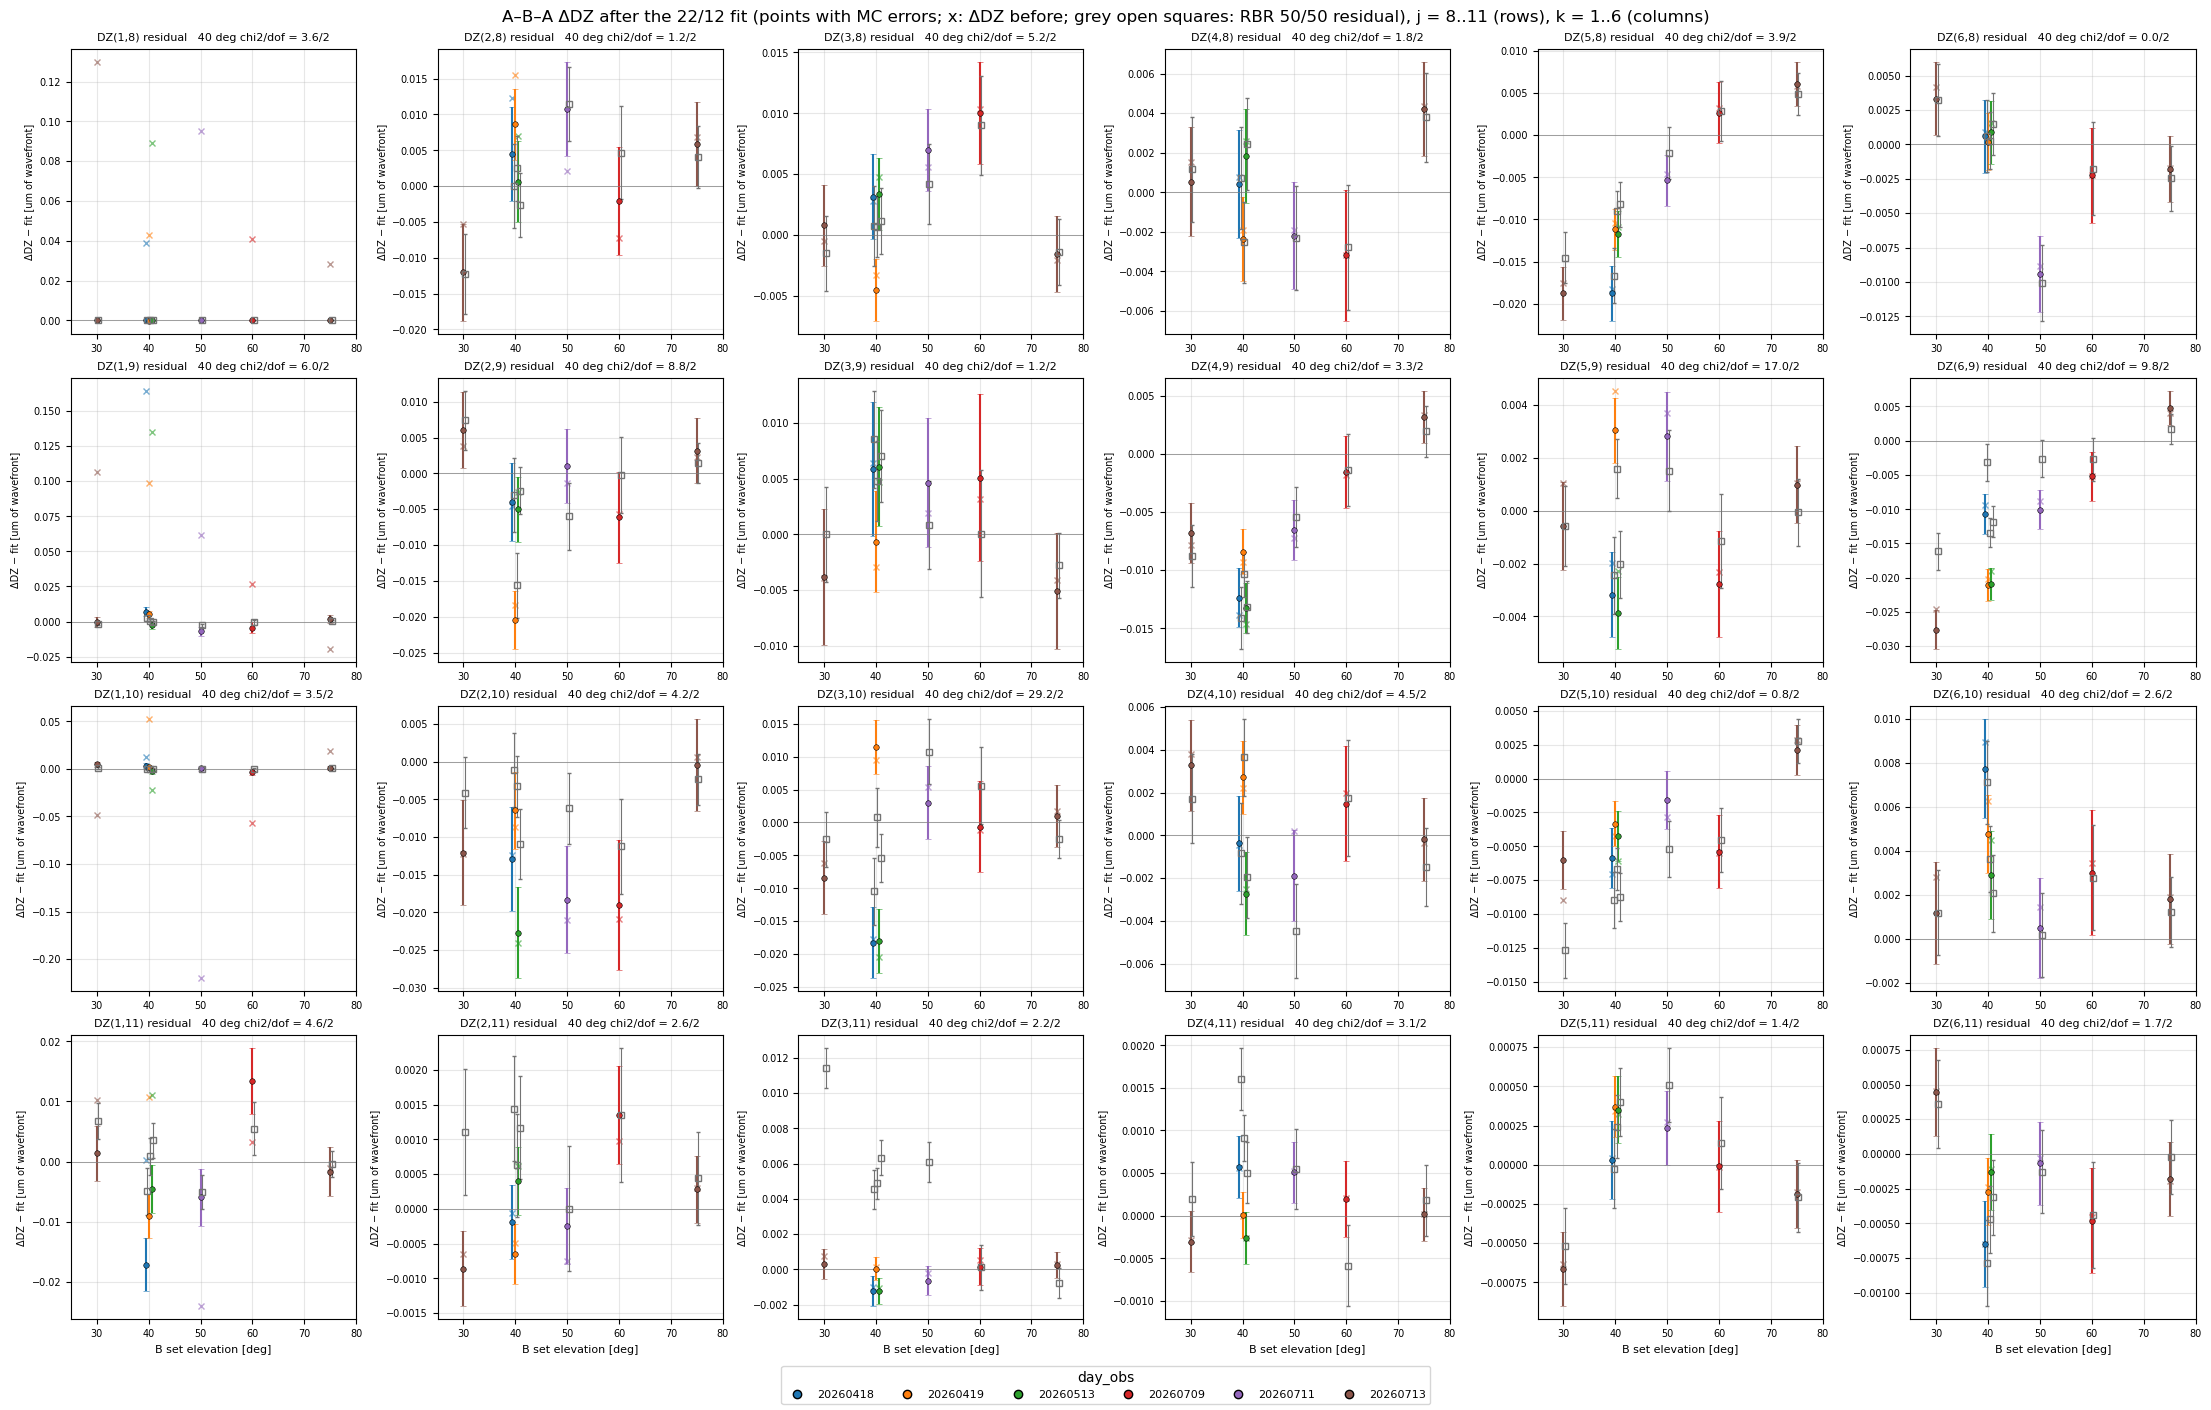

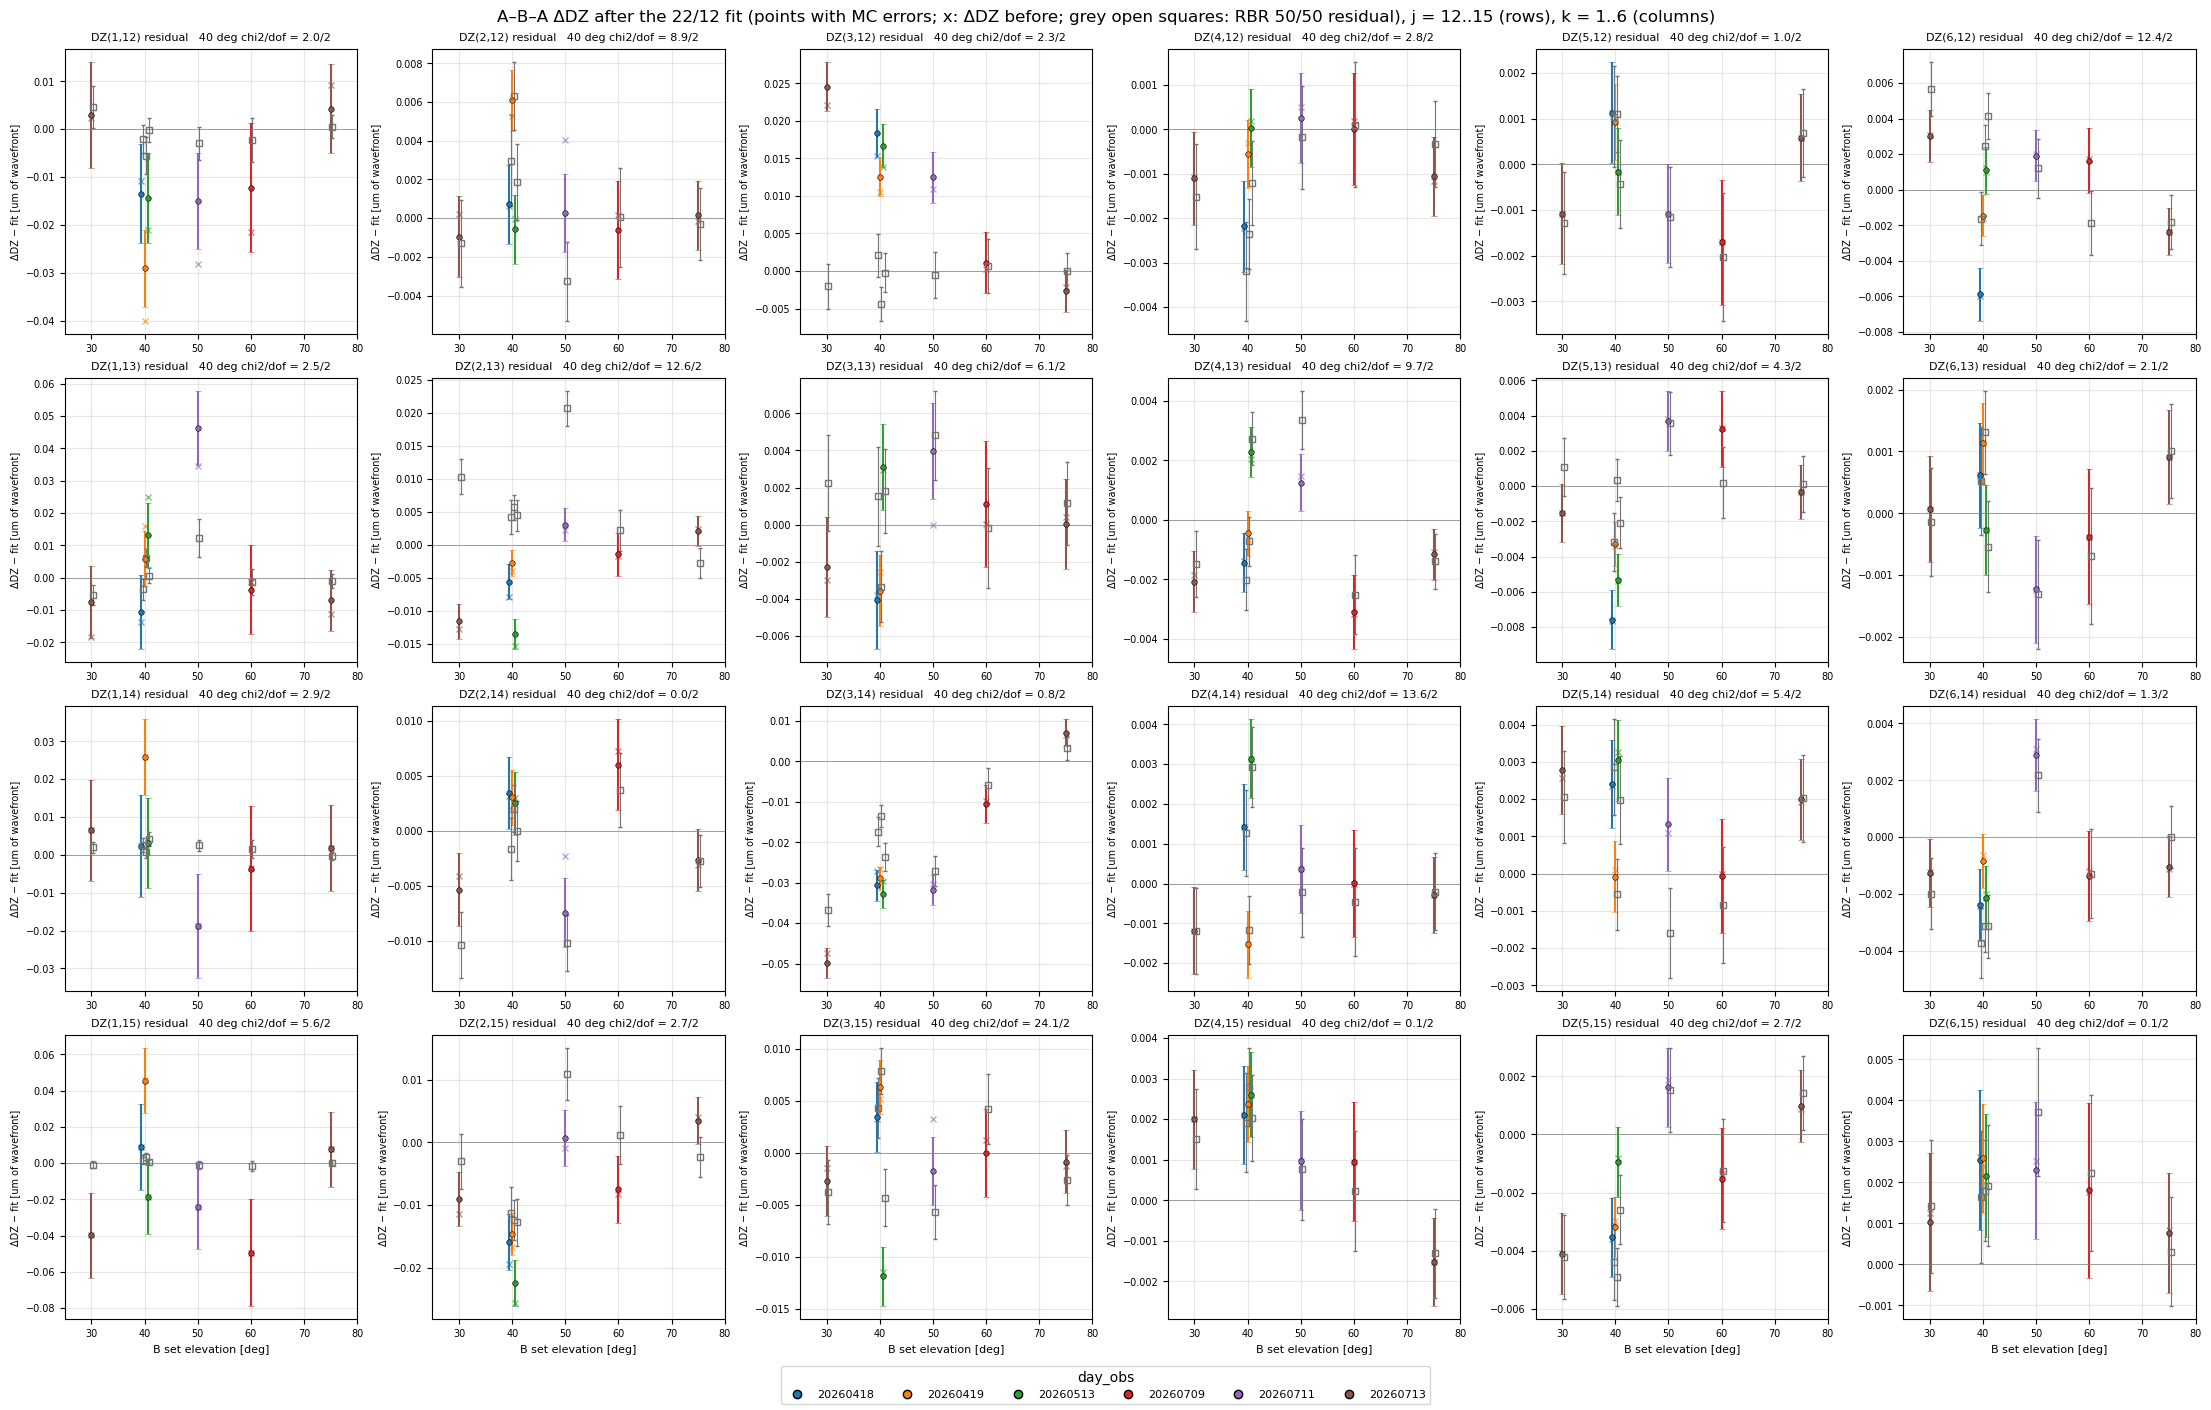

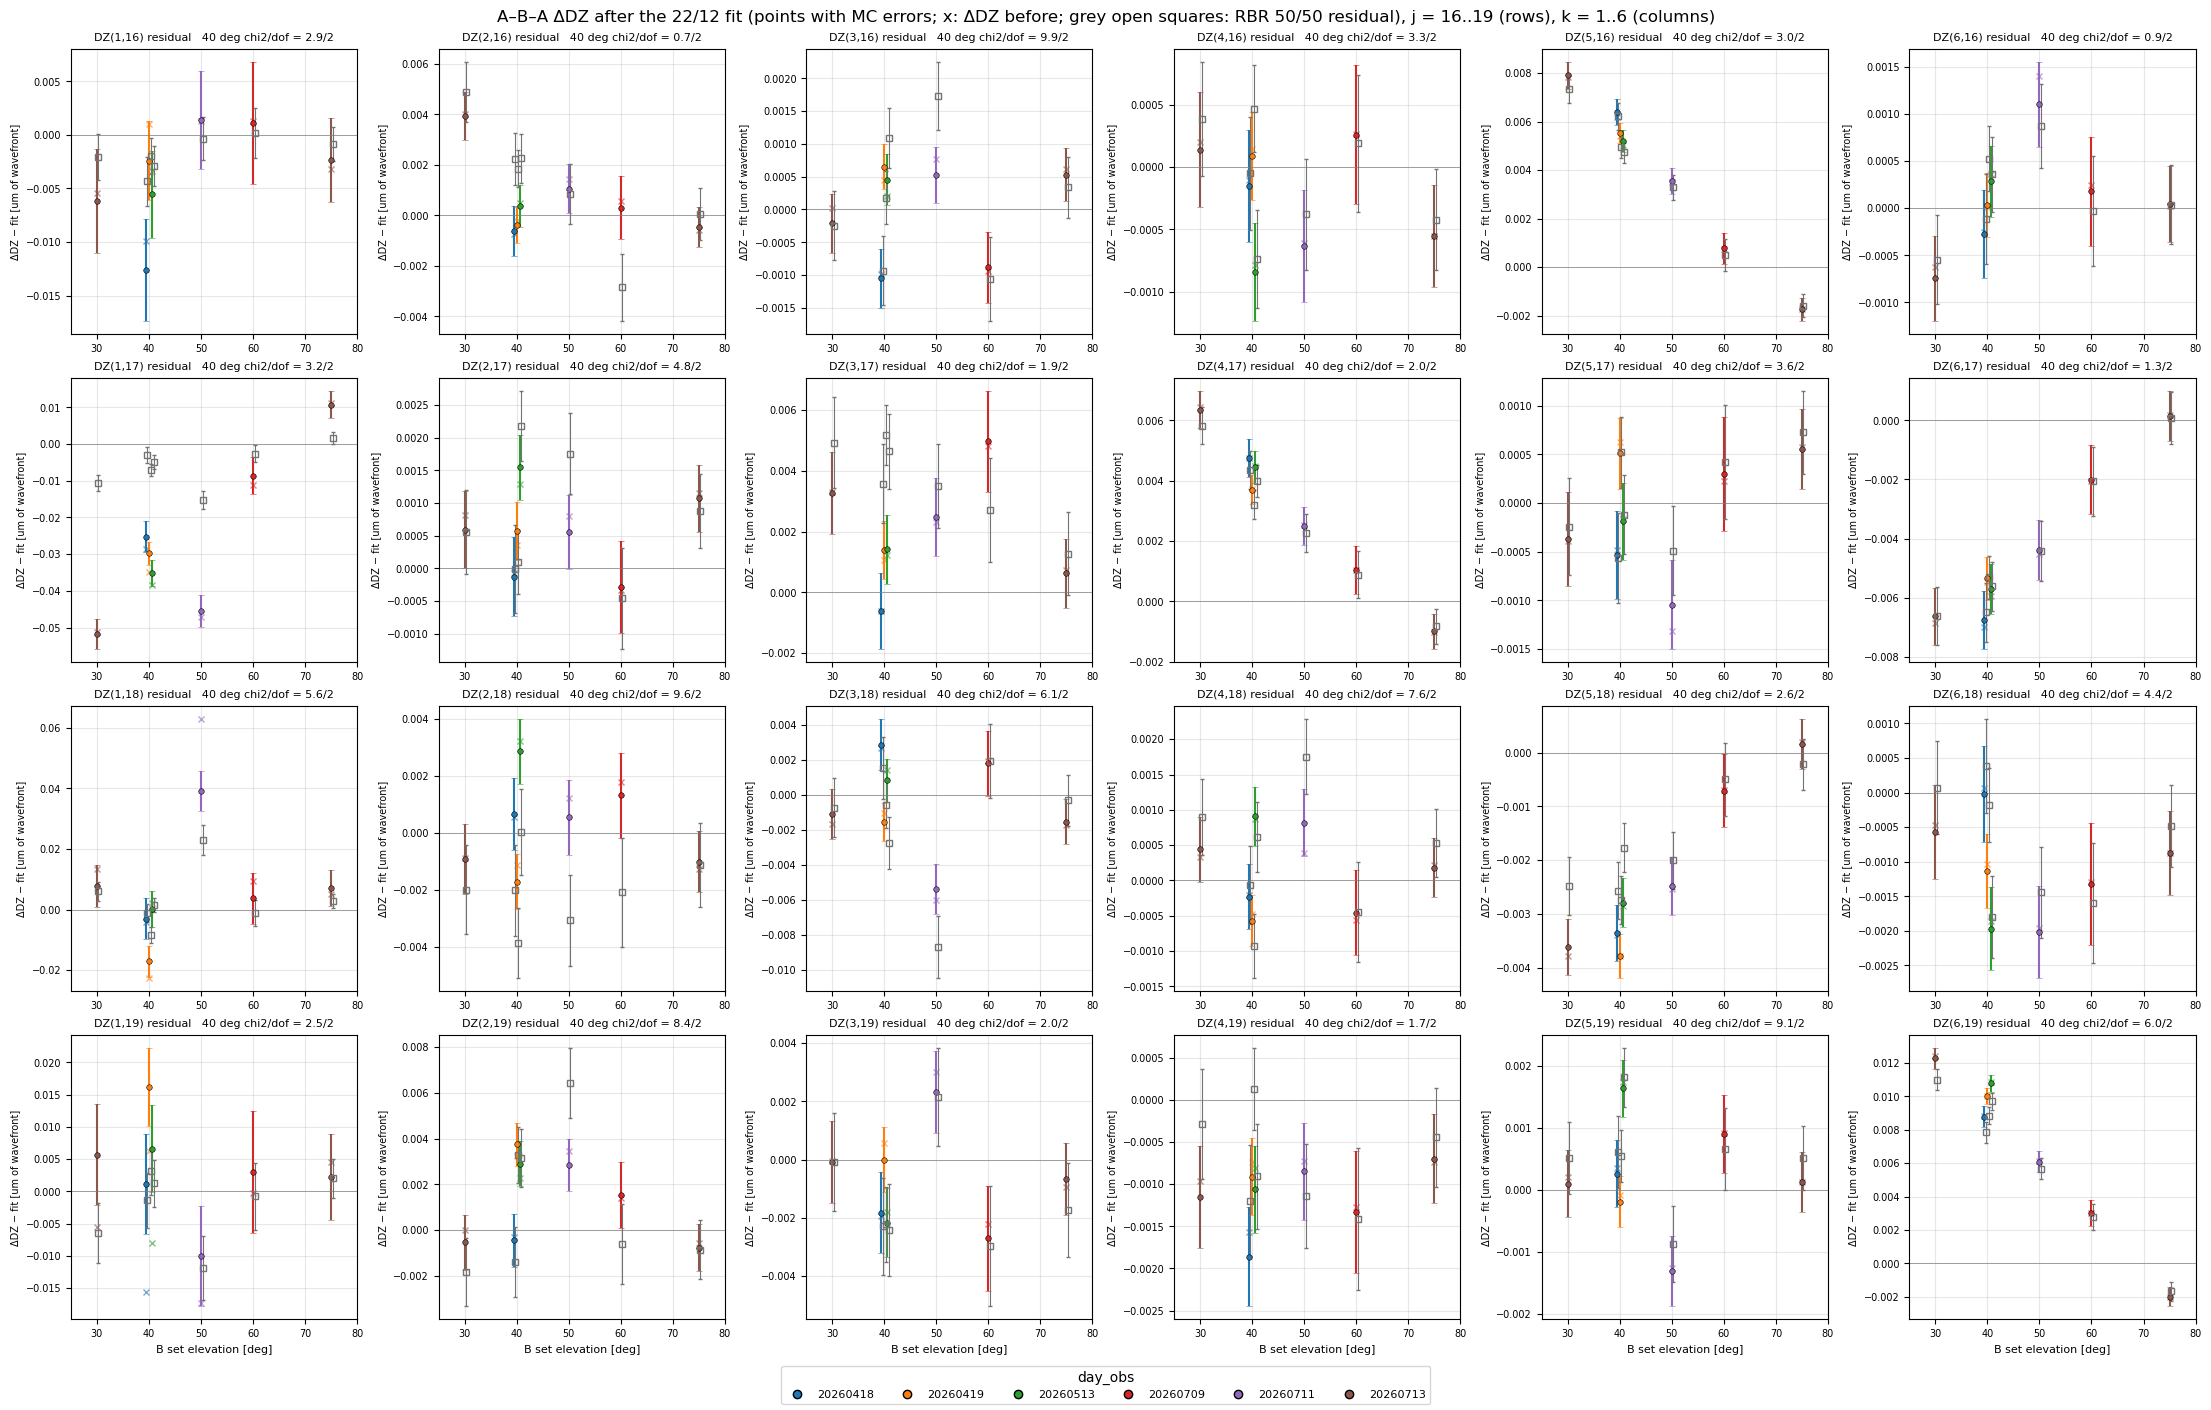

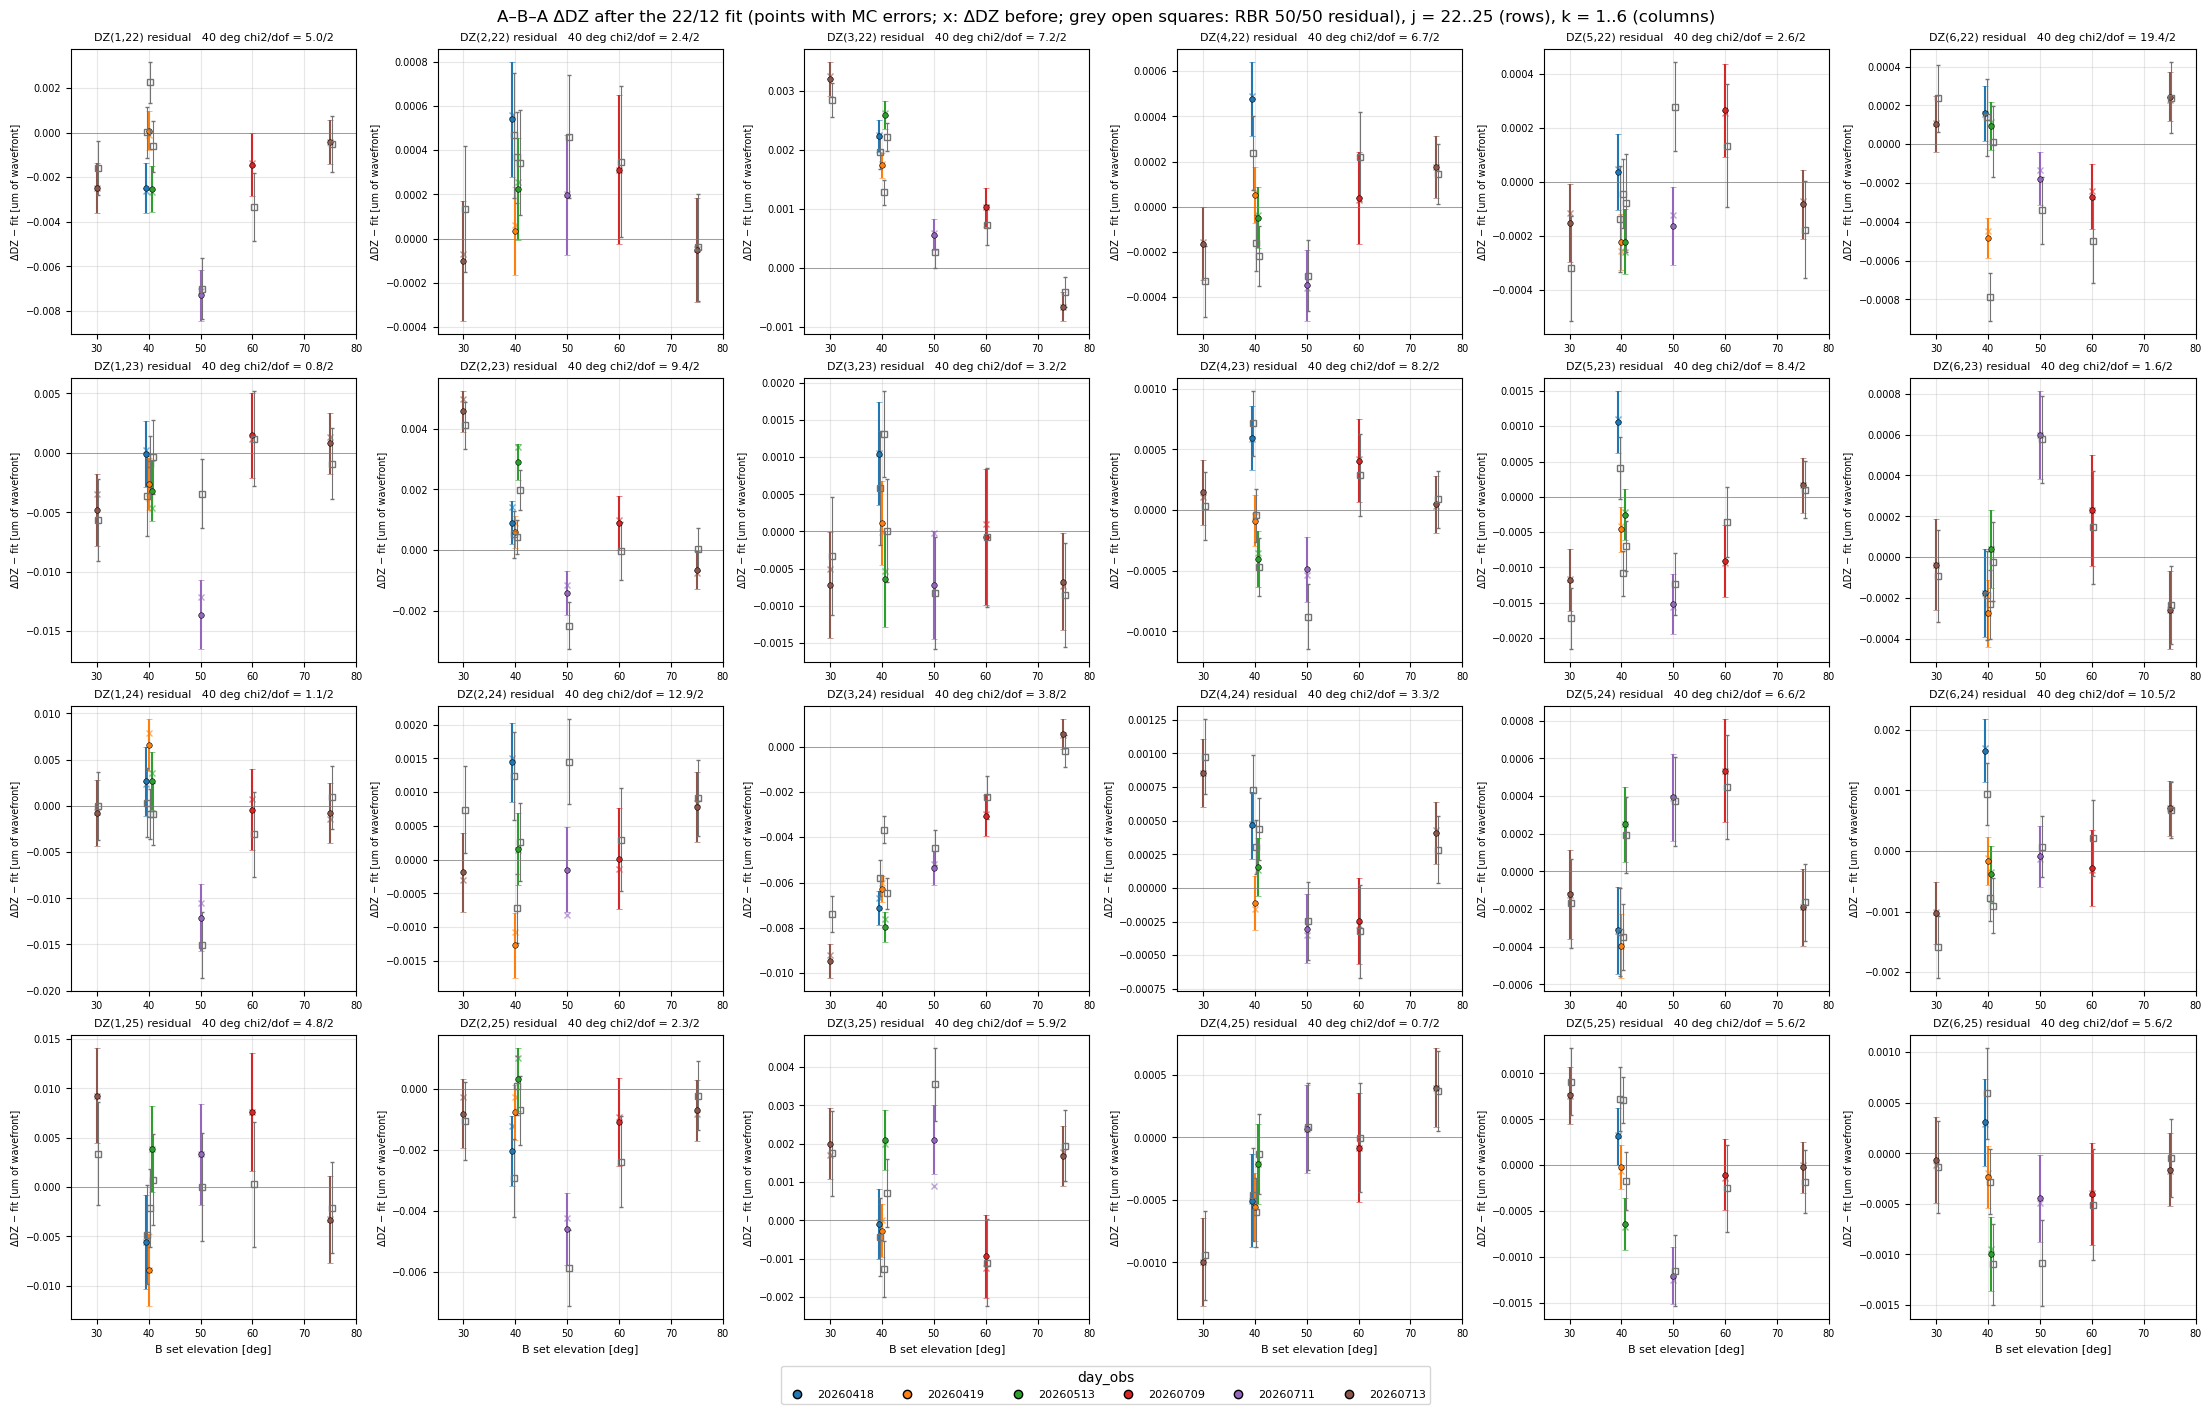

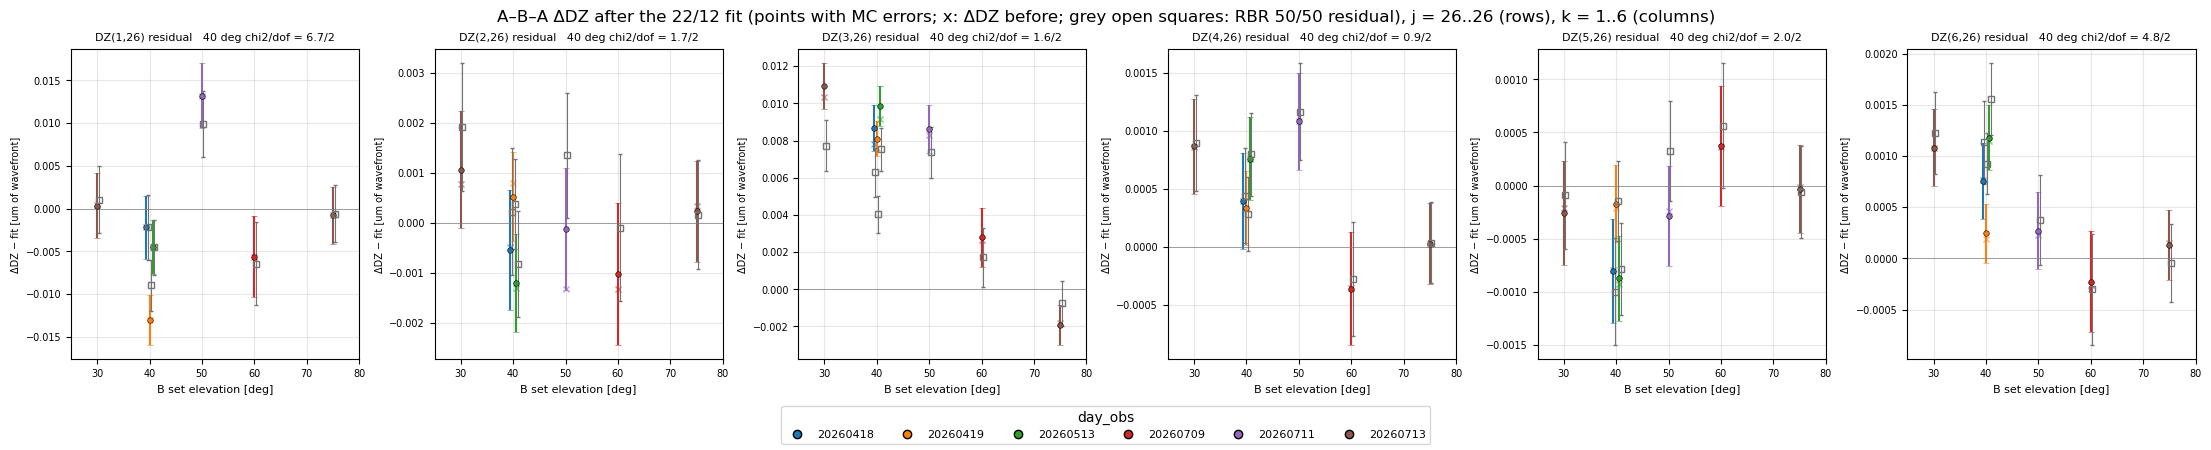

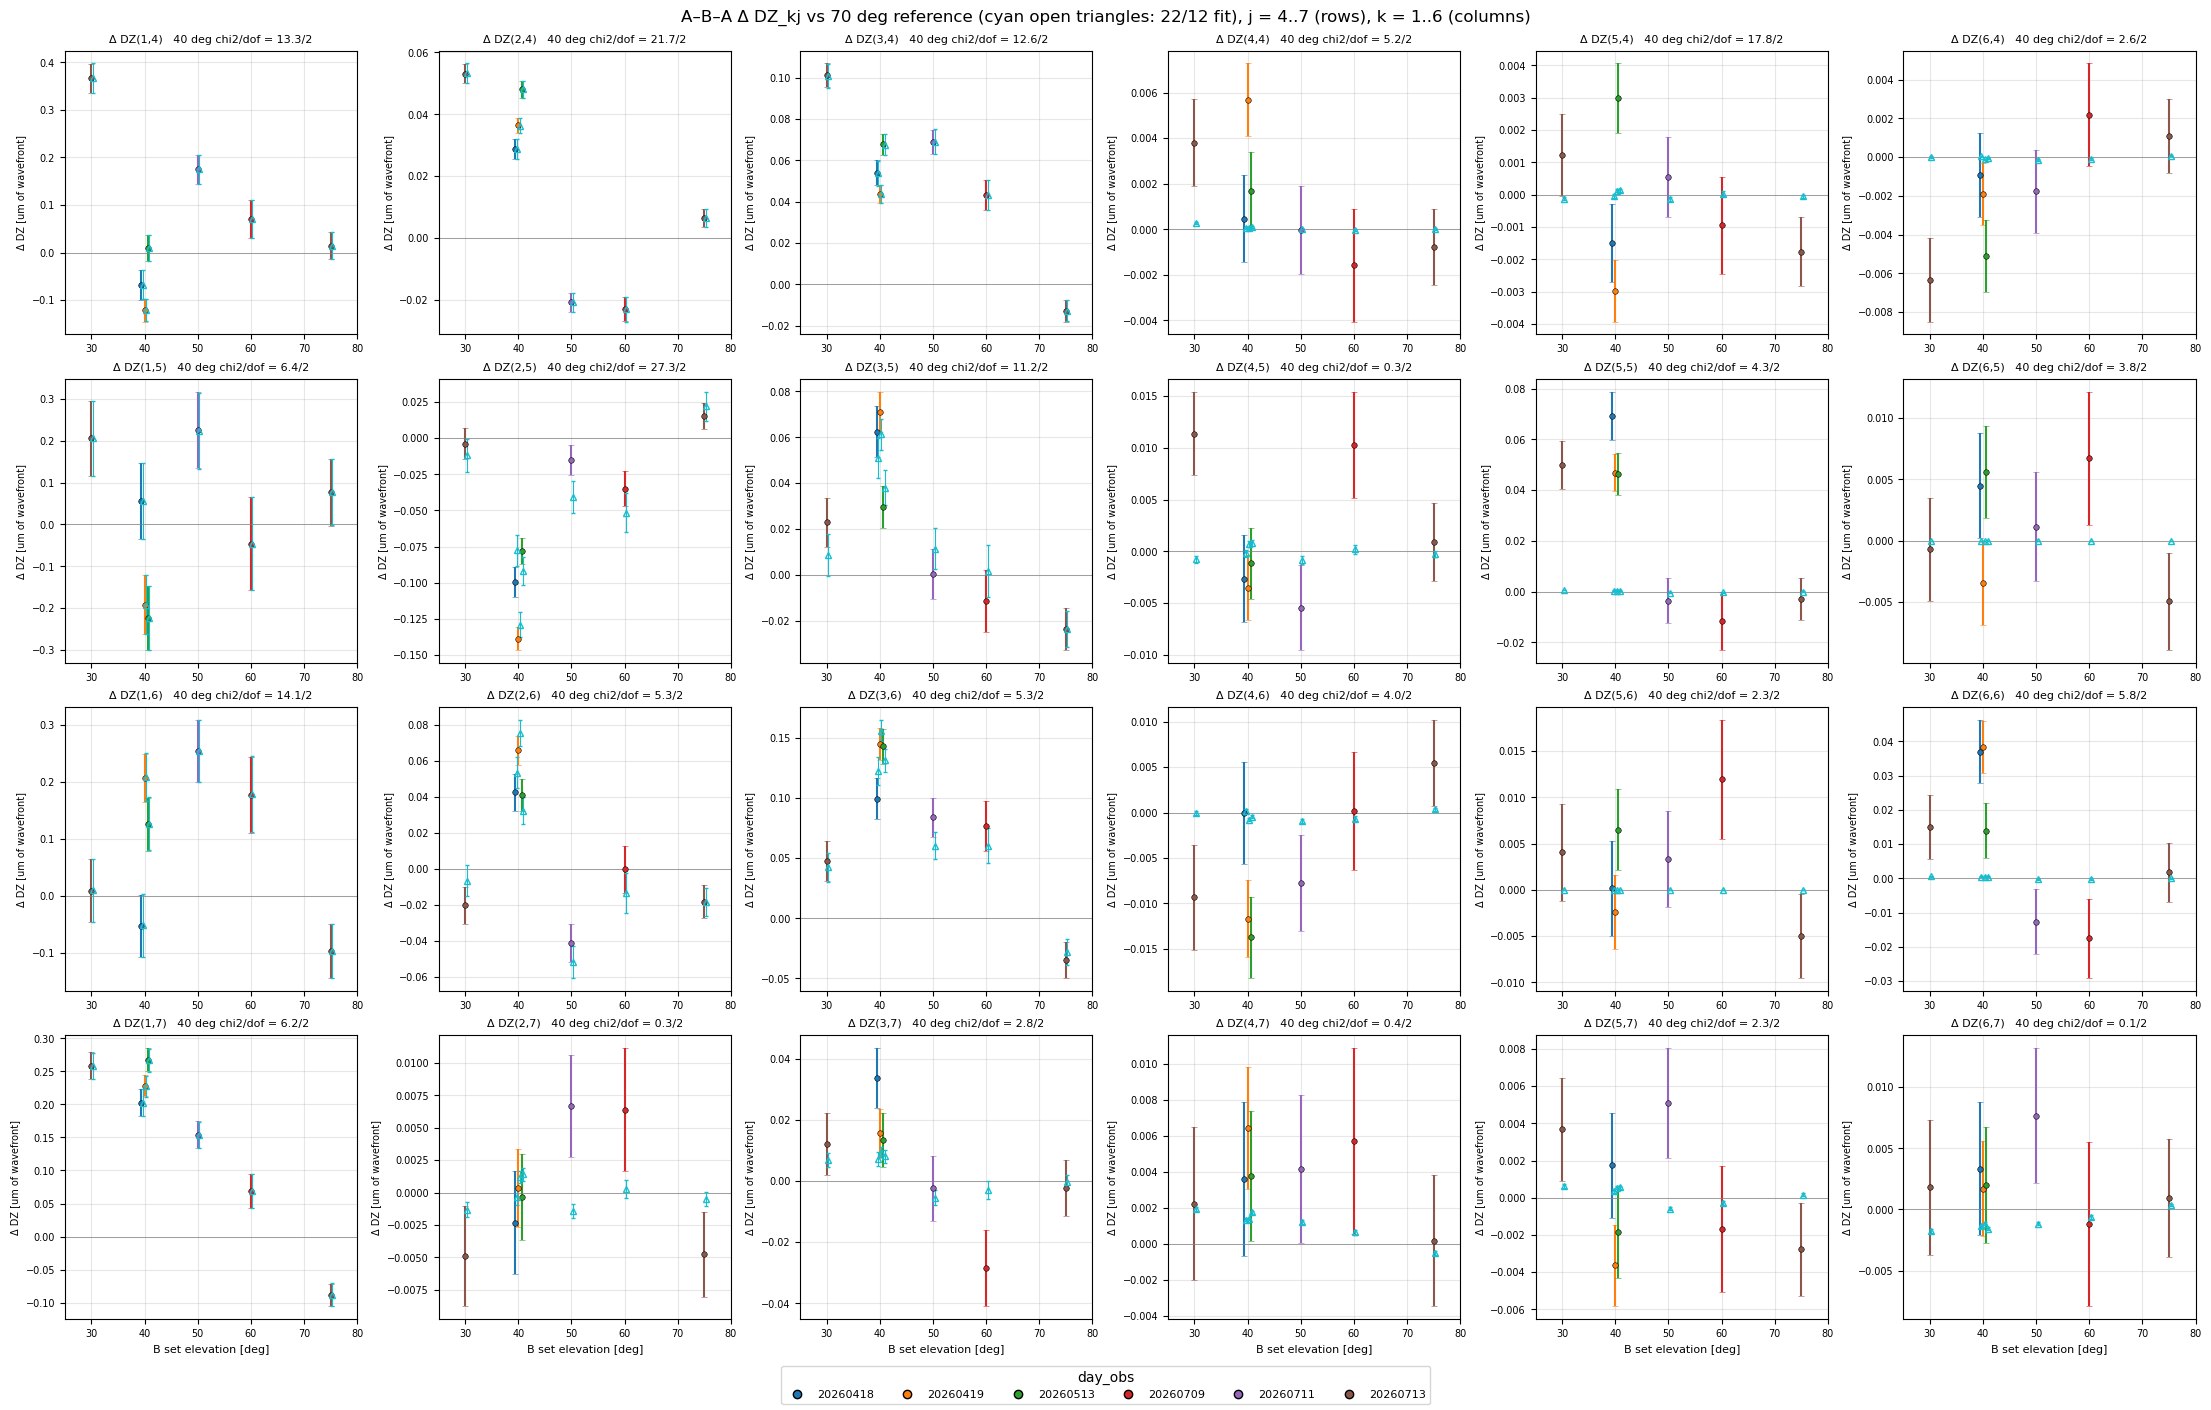

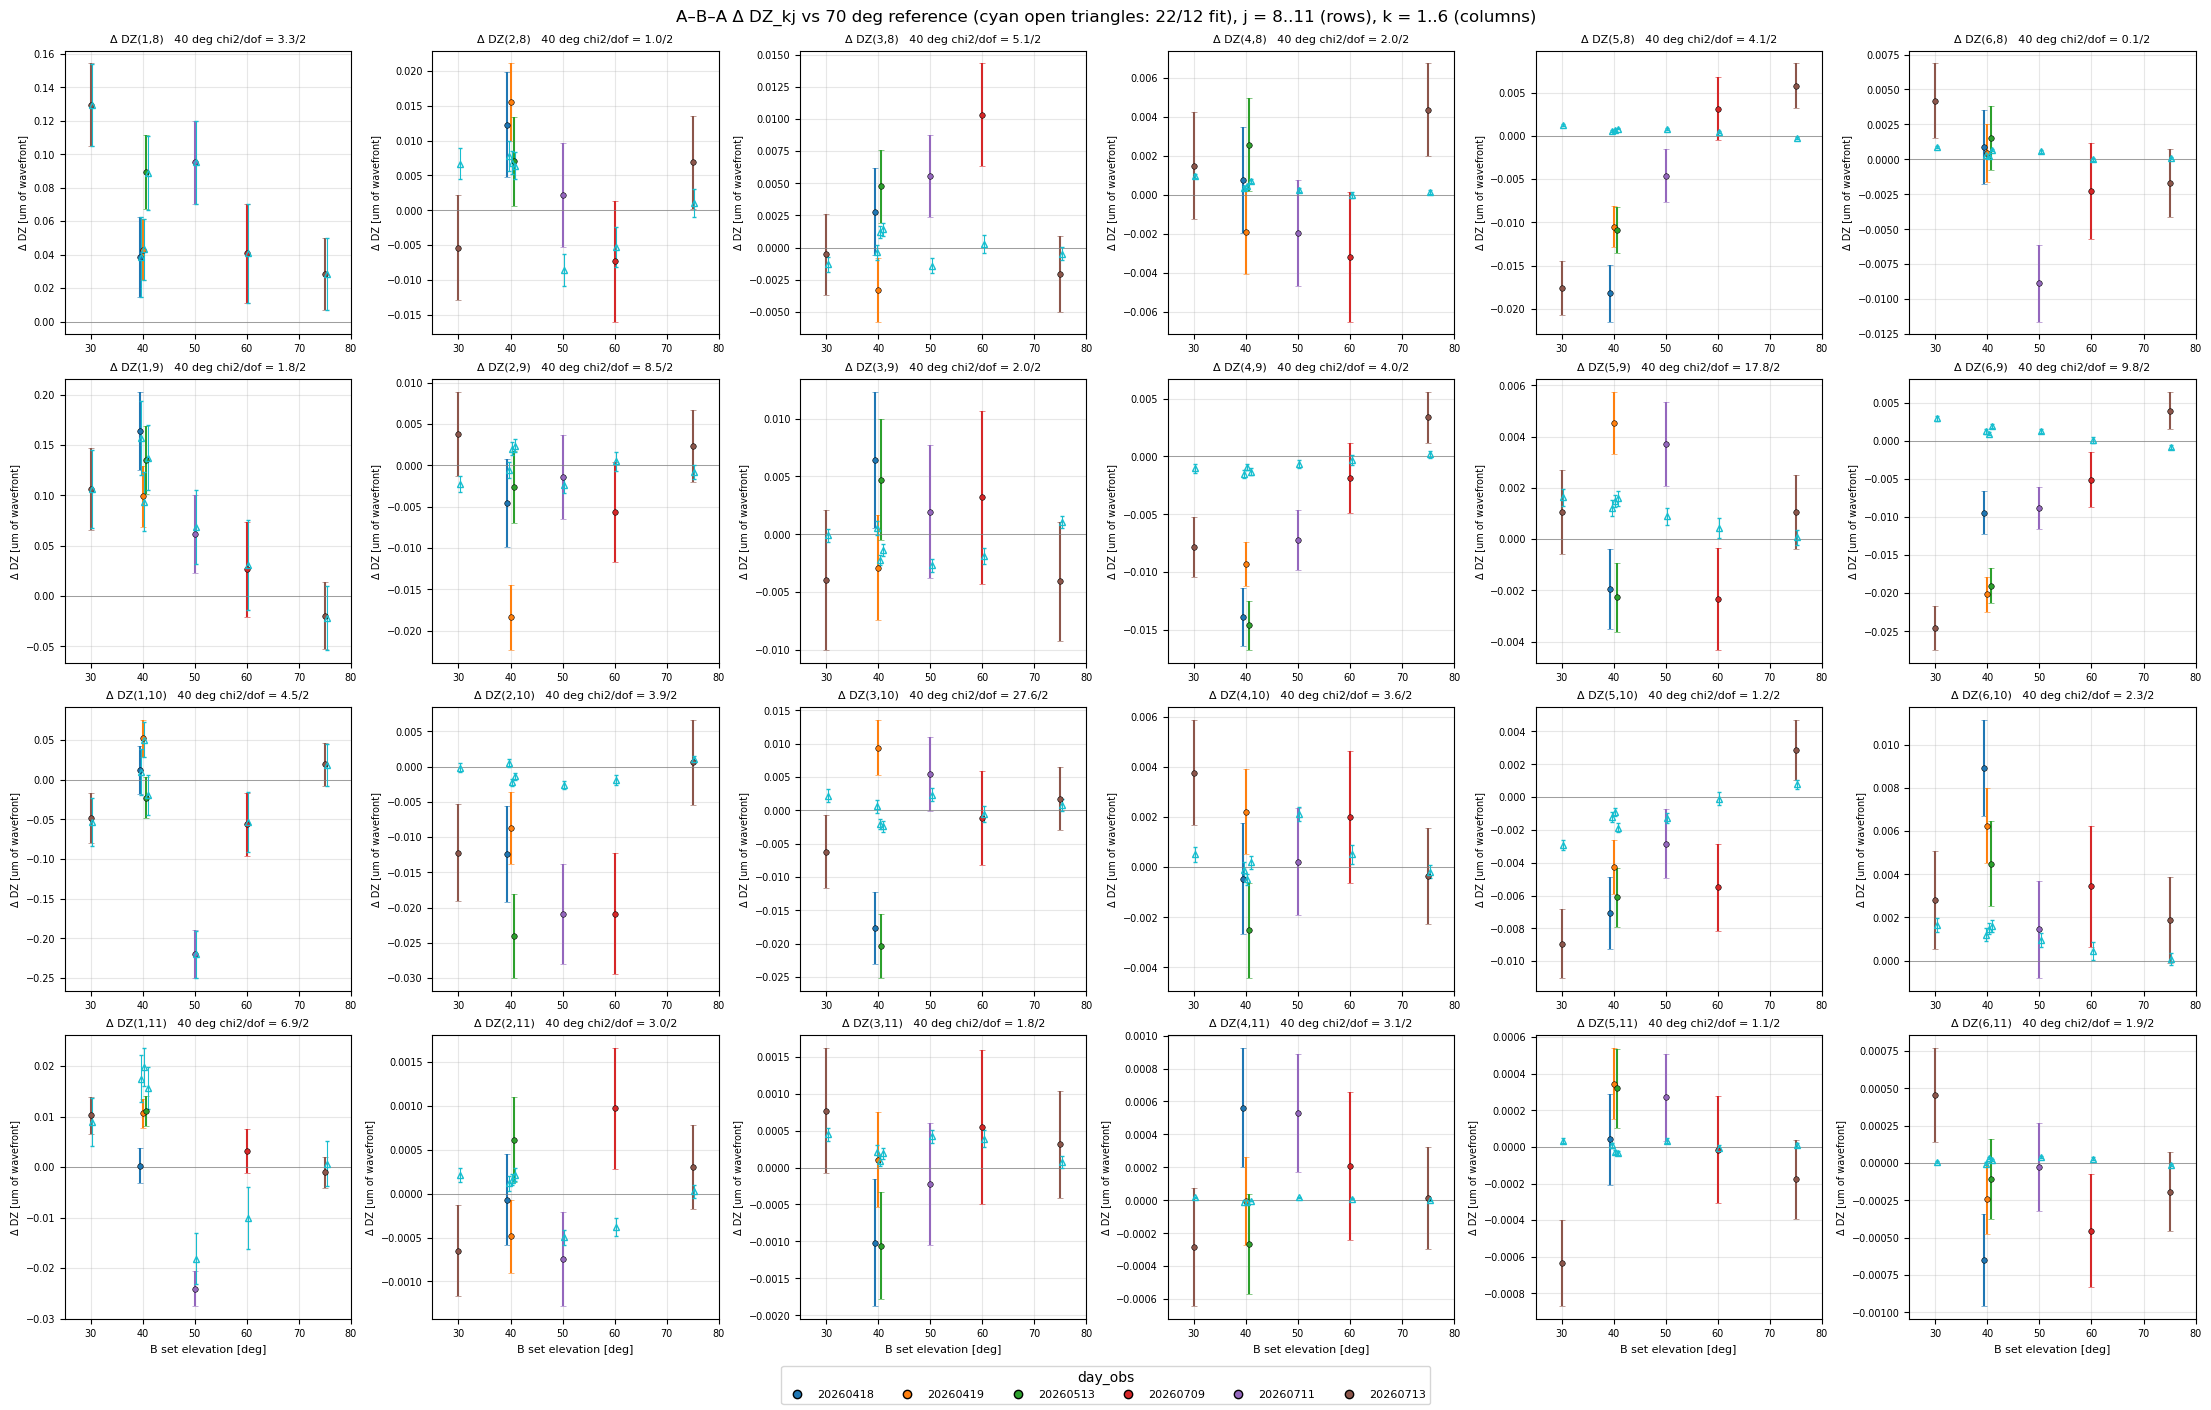

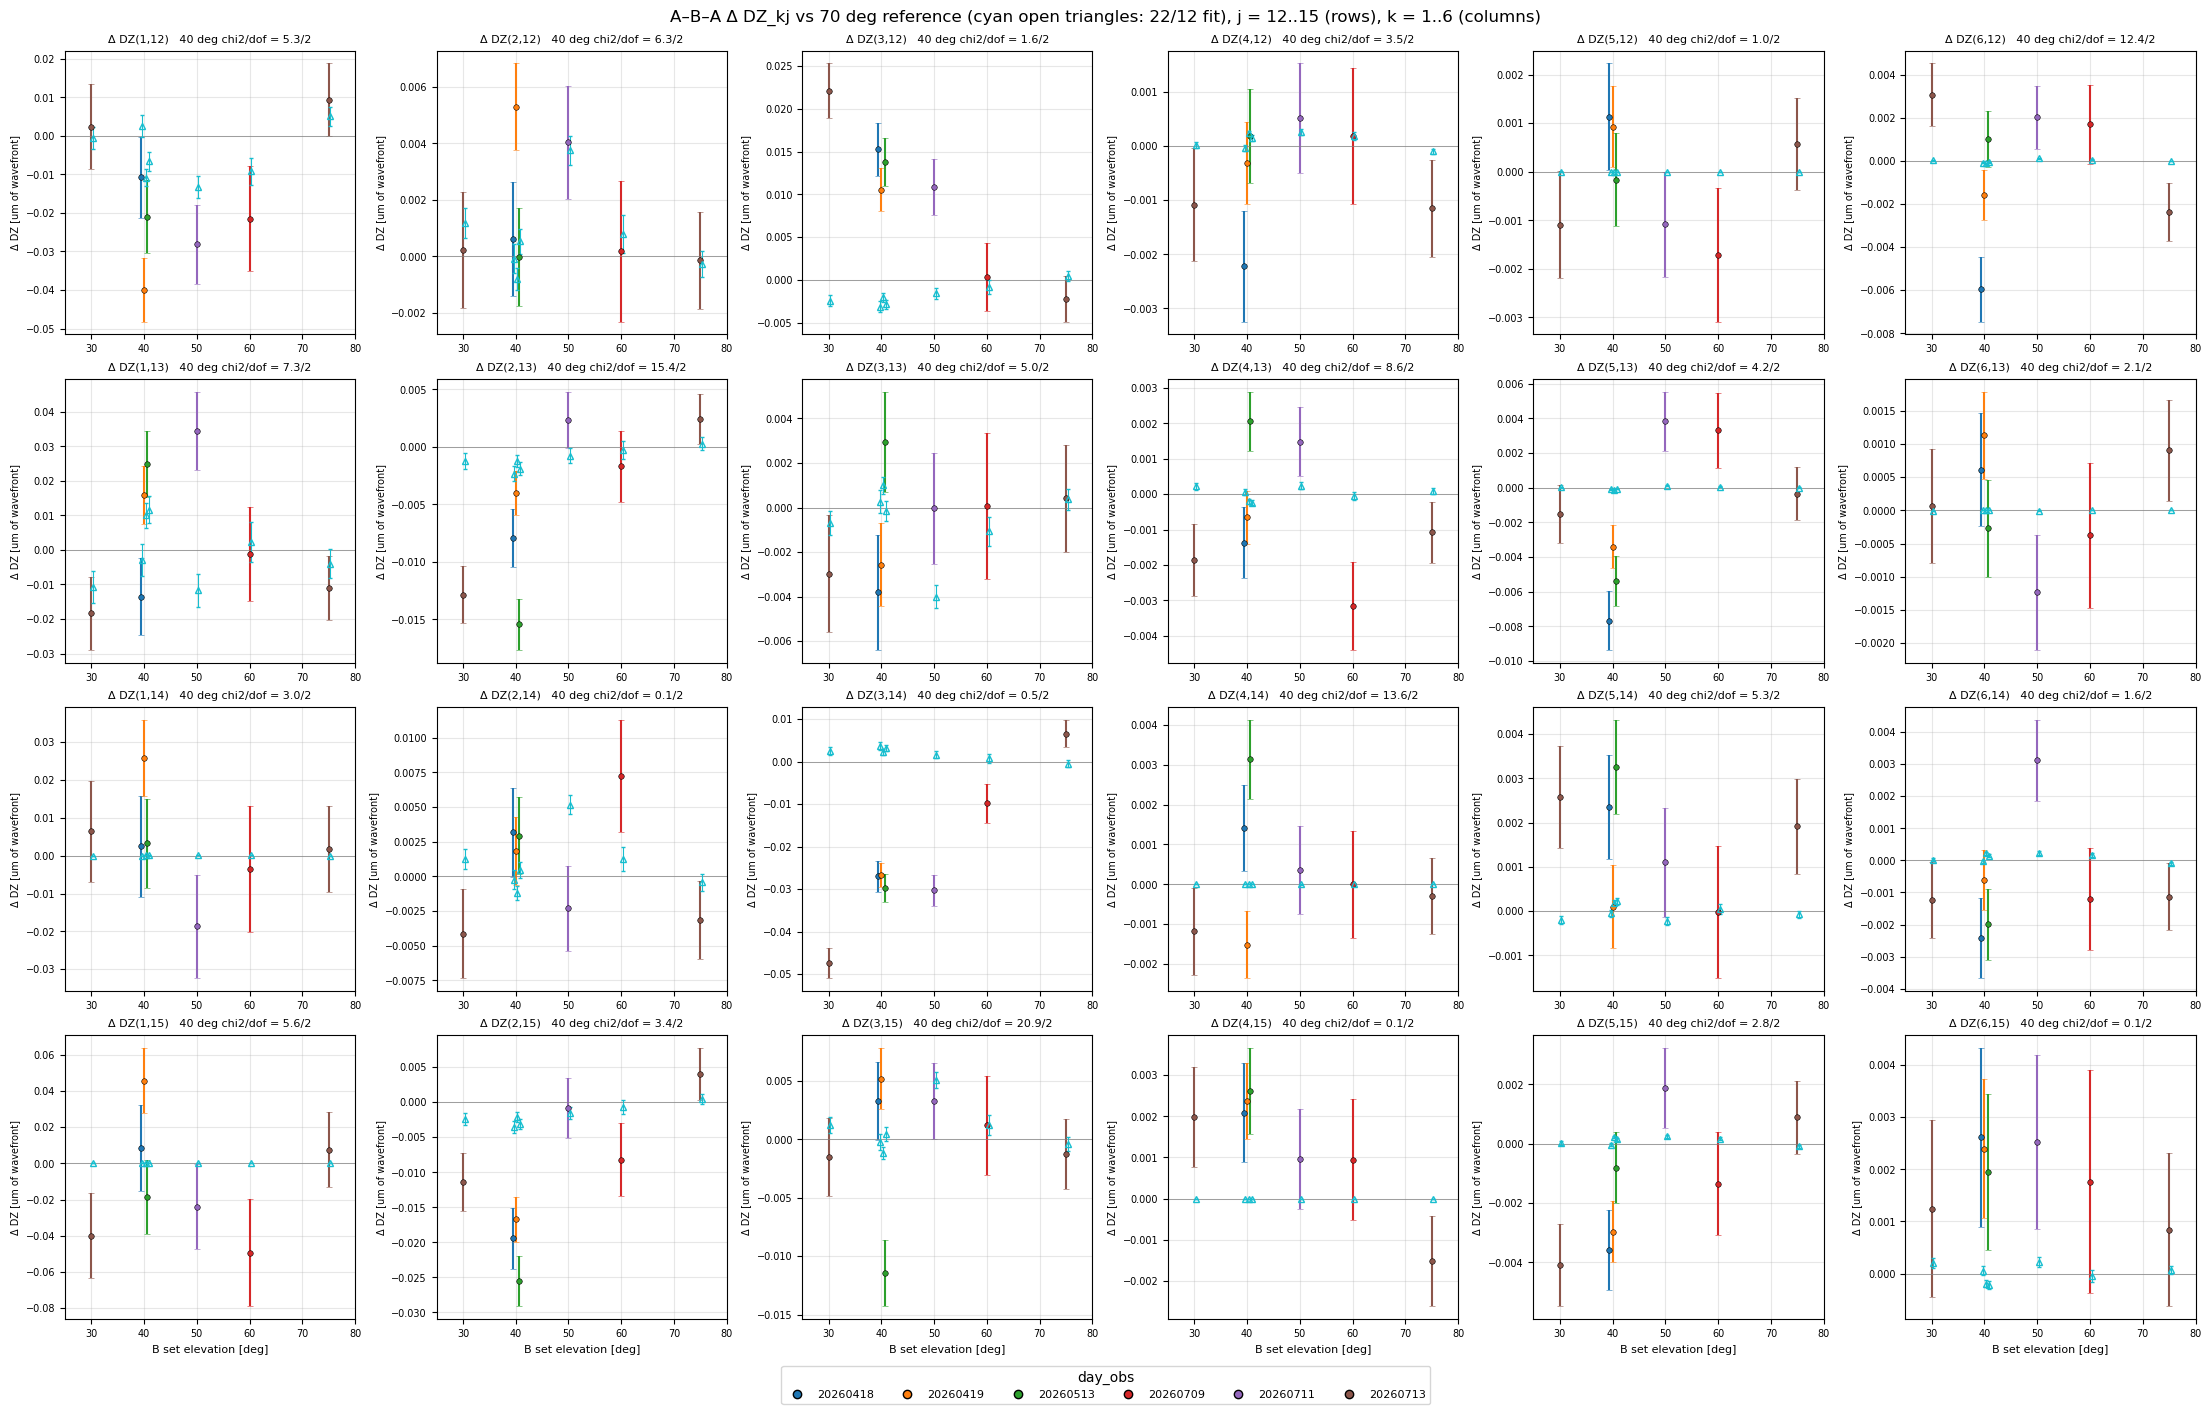

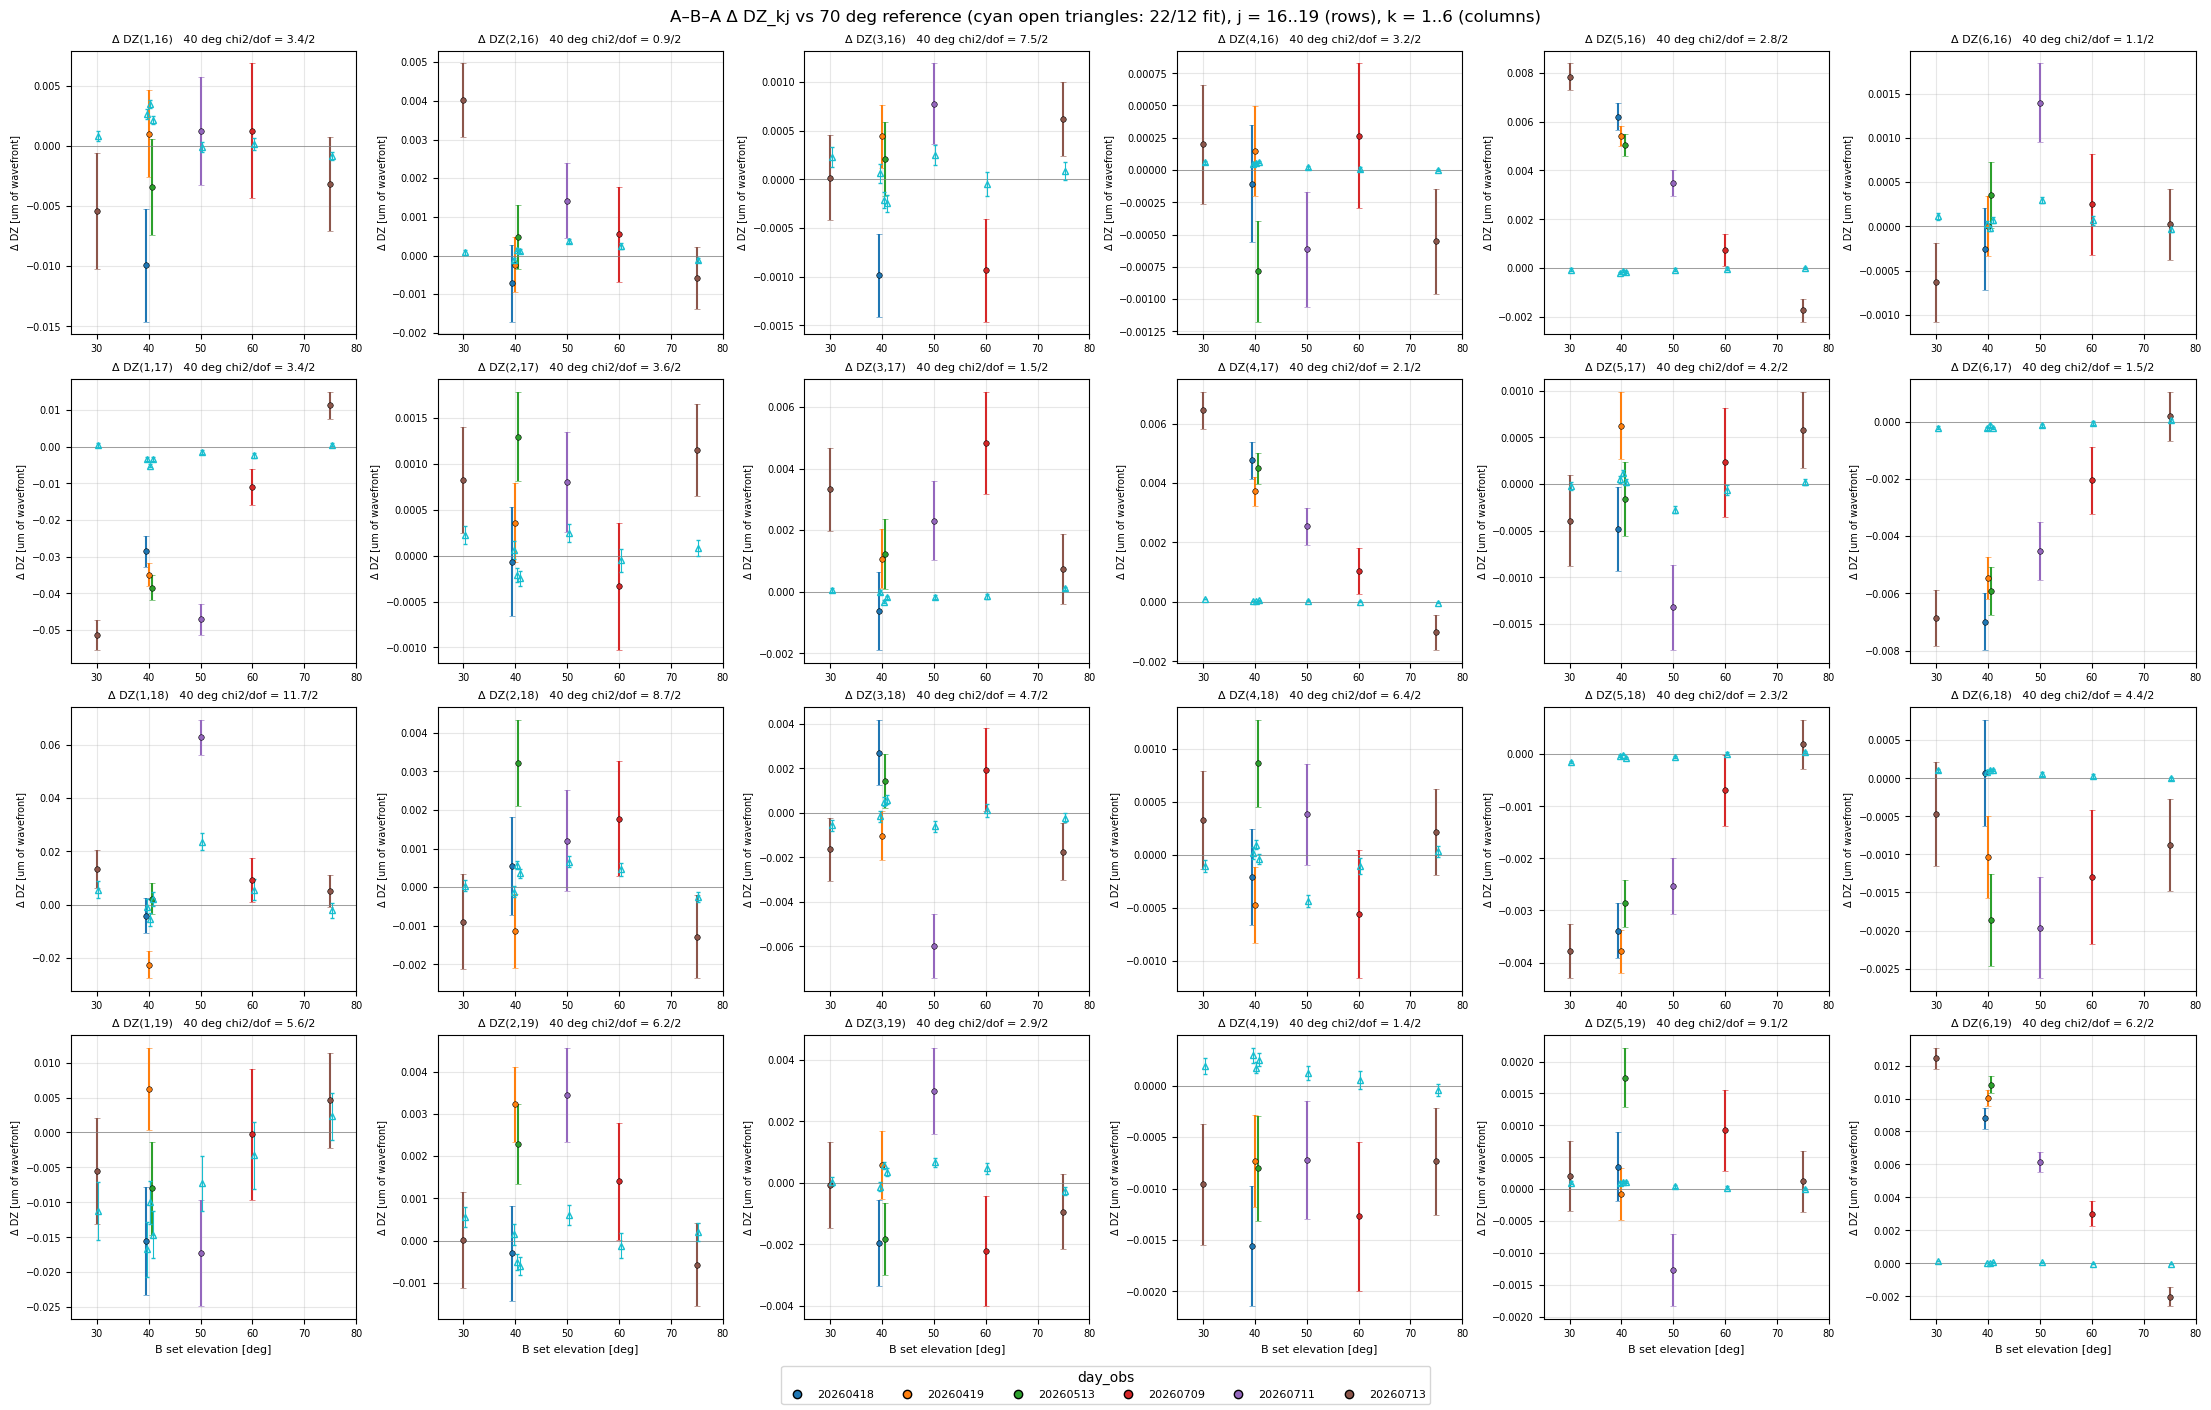

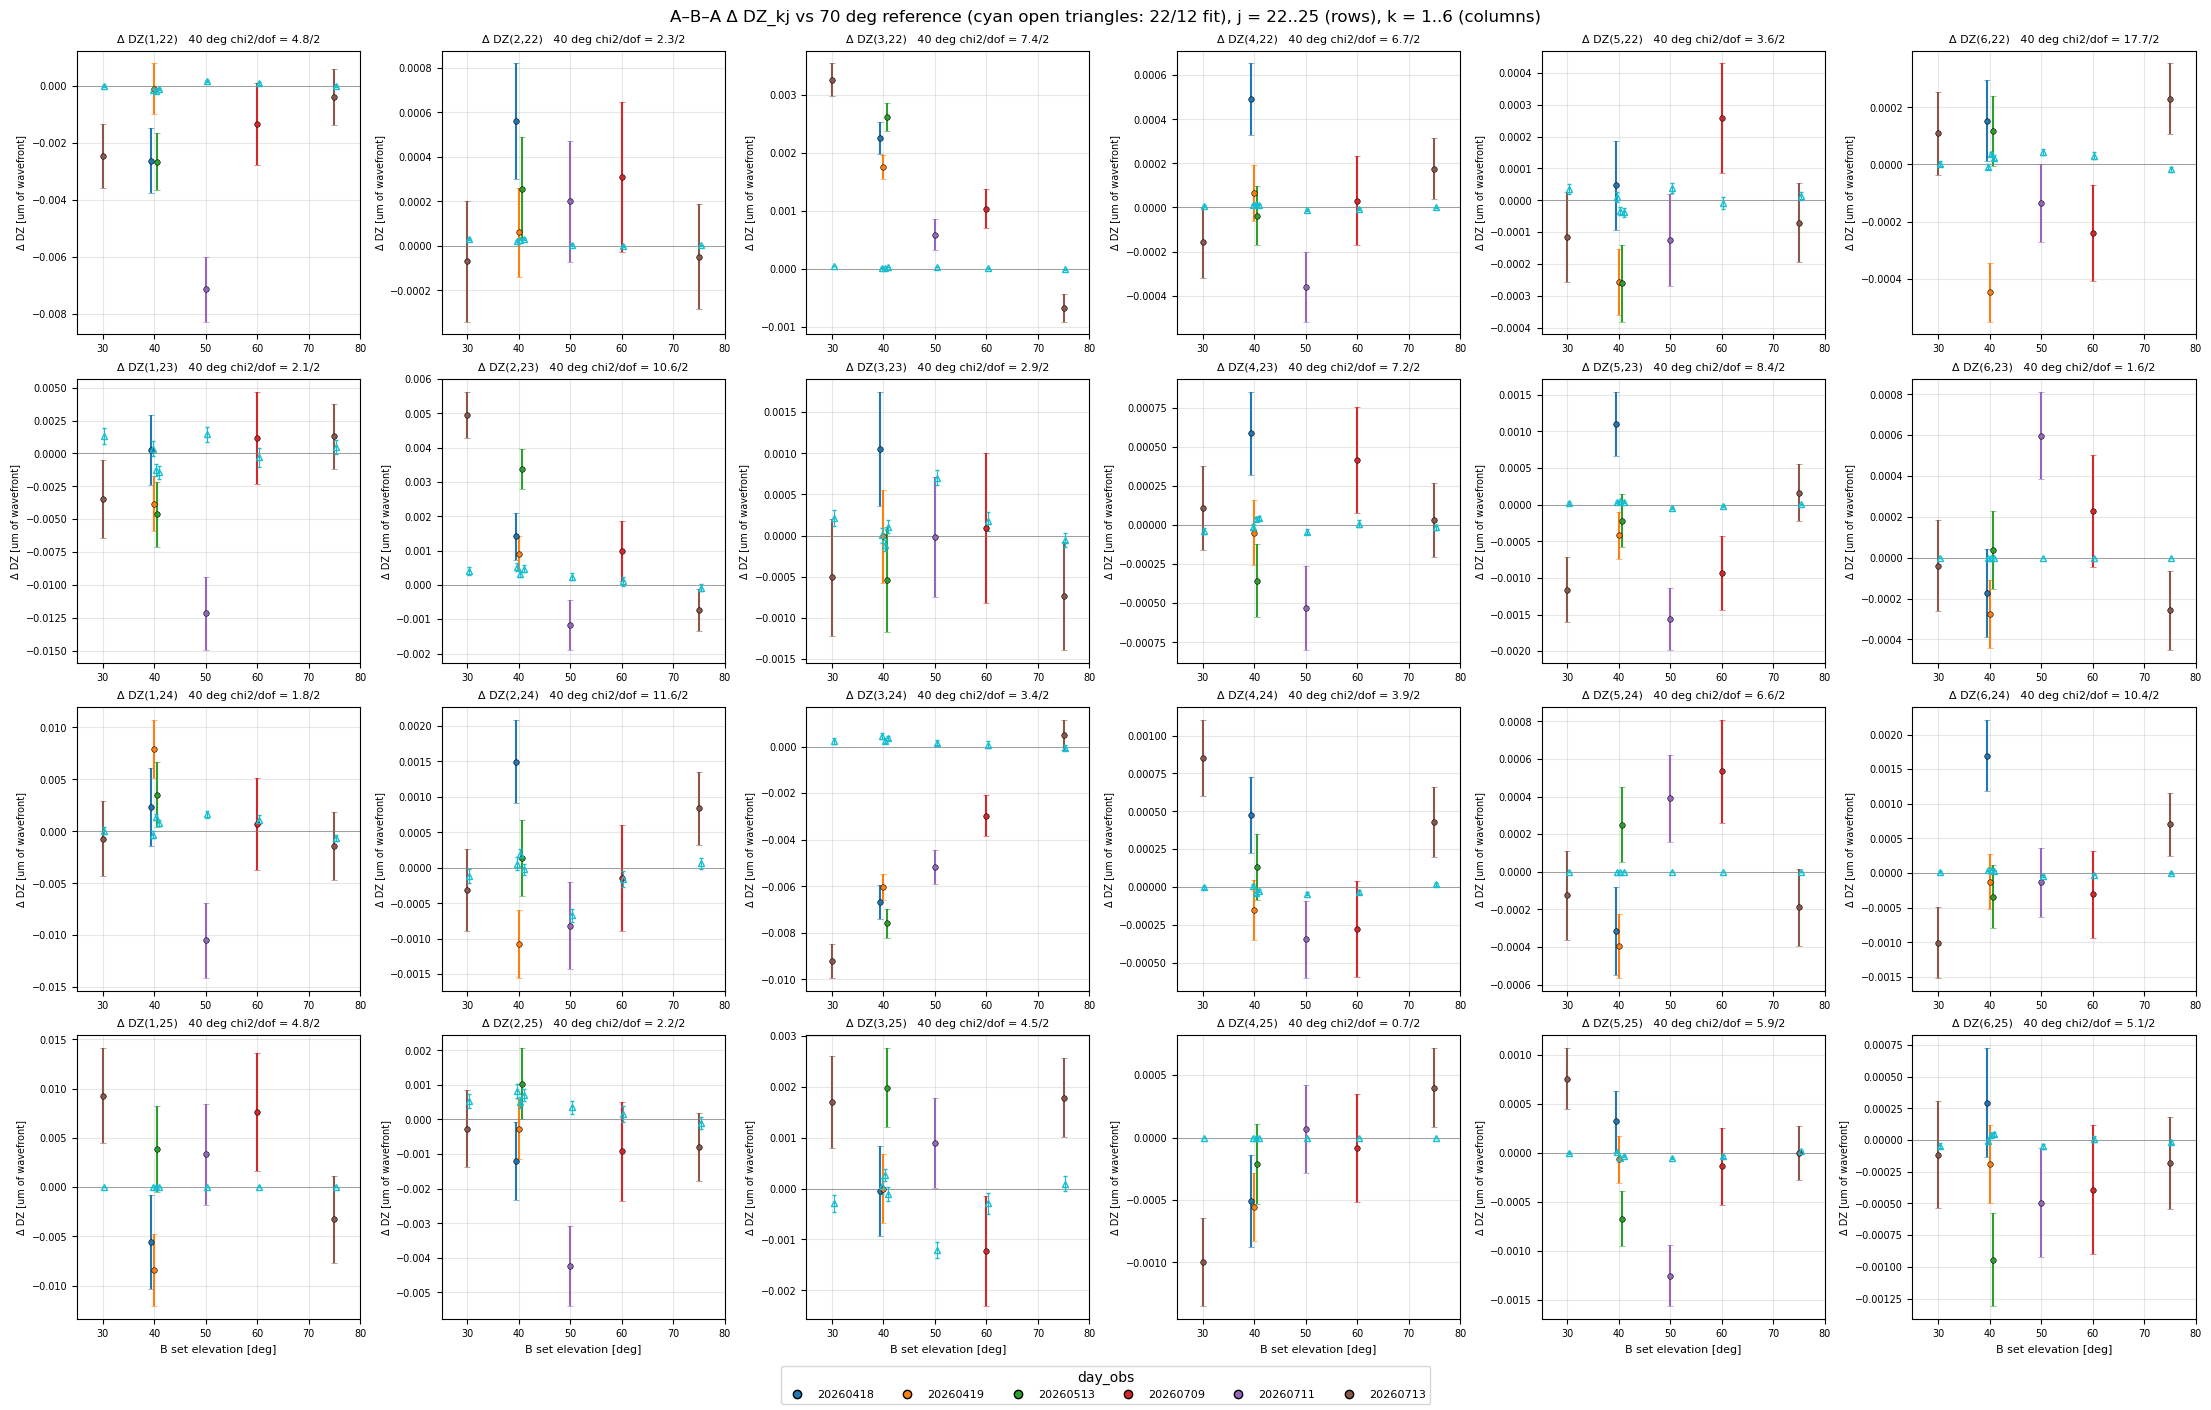

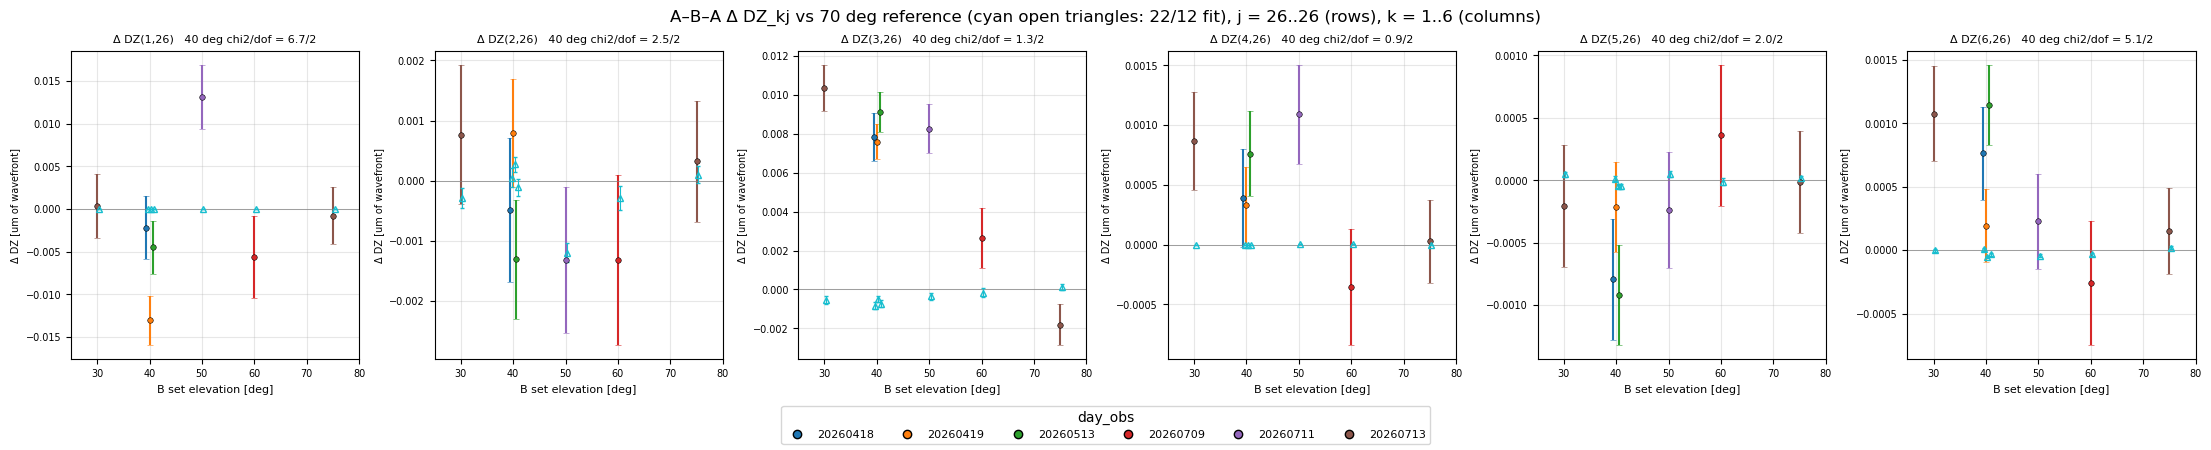

In [12]:
fig_v, axs = plt.subplots(3, 4, figsize=(20, 12), layout='constrained')
for a_, m in zip(axs.flat, range(NK)):
    panel(a_, lambda r: r['v'][m], lambda r: r['v_err'][m], f'Δ v{m + 1}', 'Δ v-mode [dimensionless]')
    a_.set_xlabel('B set elevation [deg]', fontsize=8)
fig_v.suptitle(f'Δ v-modes v1–v{NK}: 22/12 ΔDOF of the A–B–A ΔDZ, in the aos_state 22-DOF {NK}-mode v-modes')
legend_fig(fig_v); plt.show()

figs_dof = []
for idx, shape, fs in [(list(range(10)), (5, 2), (16, 17)), (list(range(10, ND)), (4, 3), (20, 14))]:
    fig, axs = plt.subplots(*shape, figsize=fs, layout='constrained')
    for a_, i in zip(axs.T.flat if shape == (5, 2) else axs.flat, idx):
        panel(a_, lambda r: r['dof'][i], lambda r: r['dof_err'][i], f'Δ {LAB[i]}', f'Δ {LAB[i]} [{UNIT[i]}]')
        overlay(a_, lambda r: r['rbr_dof'][i], lambda r: r['rbr_dof_err'][i])
        a_.set_xlabel('B set elevation [deg]', fontsize=8)
    fig.suptitle(f'Δ DOF {LAB[idx[0]]} to {LAB[idx[-1]]}: 22/12 of the A–B–A ΔDZ '
                 '(grey open squares: RBR 50/50, v3)')
    legend_fig(fig); figs_dof.append(fig); plt.show()

figs_res = []
for p0 in range(0, len(iZs), J_PER_PAGE):
    js = iZs[p0:p0 + J_PER_PAGE]
    fig, axs = plt.subplots(len(js), len(ks), figsize=(22, 3.2 * len(js) + 1.2), layout='constrained',
                            squeeze=False)
    for ri, j in enumerate(js):
        for ci, k in enumerate(ks):
            ix = KJ.index((k, j)); a_ = axs[ri, ci]
            for L in legs:
                a_.plot(L['b_value_deg'] + xoff.get(L['night'], 0.0), res[(L['night'], L['leg'])]['dz'][ix],
                        'x', color=ncol[L['night']], ms=5, alpha=0.6)
            panel(a_, lambda r: r['resid'][ix], lambda r: r['resid_err'][ix], f'DZ({k},{j}) residual',
                  'ΔDZ − fit [um of wavefront]')
            overlay(a_, lambda r: r['rbr_resid'][ix], lambda r: r['rbr_resid_err'][ix])
            if ri == len(js) - 1:
                a_.set_xlabel('B set elevation [deg]', fontsize=8)
    fig.suptitle(f'A–B–A ΔDZ after the 22/12 fit (points with MC errors; x: ΔDZ before; grey open squares: '
                 f'RBR 50/50 residual), j = {js[0]}..{js[-1]} (rows), k = 1..6 (columns)')
    legend_fig(fig); figs_res.append(fig); plt.show()

figs_dz = []
for p0 in range(0, len(iZs), J_PER_PAGE):
    js = iZs[p0:p0 + J_PER_PAGE]
    fig, axs = plt.subplots(len(js), len(ks), figsize=(22, 3.2 * len(js) + 1.2), layout='constrained',
                            squeeze=False)
    for ri, j in enumerate(js):
        for ci, k in enumerate(ks):
            ix = KJ.index((k, j))
            panel(axs[ri, ci], lambda r: r['dz'][ix], lambda r: r['dz_err'][ix], f'Δ DZ({k},{j})',
                  'Δ DZ [um of wavefront]')
            overlay(axs[ri, ci], lambda r: r['fit'][ix], lambda r: r['fit_err'][ix], fmt='^', color='tab:cyan')
            if ri == len(js) - 1:
                axs[ri, ci].set_xlabel('B set elevation [deg]', fontsize=8)
    fig.suptitle(f'A–B–A Δ DZ_kj vs 70 deg reference (cyan open triangles: 22/12 fit), '
                 f'j = {js[0]}..{js[-1]} (rows), k = 1..6 (columns)')
    legend_fig(fig); figs_dz.append(fig); plt.show()

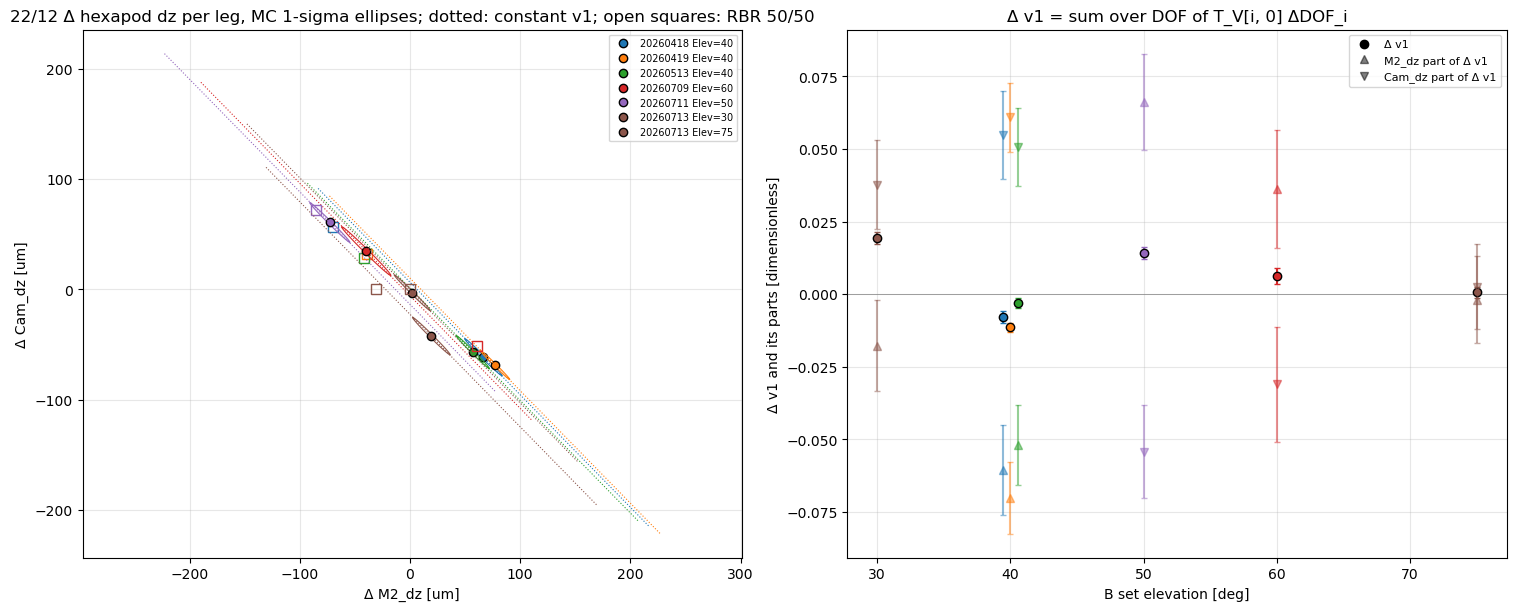

In [13]:
fig_split, ax = plt.subplots(1, 2, figsize=(15, 6), layout='constrained')
for L in legs:
    r = res[(L['night'], L['leg'])]; c = ncol[L['night']]
    x, y = r['dof'][0], r['dof'][5]
    C2 = np.cov(r['dof_mc'][:, [0, 5]].T); e, U = np.linalg.eigh(C2)
    th = np.linspace(0, 2 * np.pi, 100); el = U @ (np.sqrt(e)[:, None] * np.array([np.cos(th), np.sin(th)]))
    ax[0].plot(x + el[0], y + el[1], '-', color=c, lw=0.8)
    ax[0].plot(x, y, 'o', color=c, mec='k', label=f"{L['night']} {L['leg']}")
    ax[0].plot(r['rbr_dof'][0], r['rbr_dof'][5], 's', mfc='none', color=c, ms=7)
    s_ = np.linspace(-150, 150, 2)
    ax[0].plot(x + s_, y - s_ * T_V[0, 0] / T_V[5, 0], ':', color=c, lw=0.8)
ax[0].set_xlabel('Δ M2_dz [um]'); ax[0].set_ylabel('Δ Cam_dz [um]')
ax[0].set_title('22/12 Δ hexapod dz per leg, MC 1-sigma ellipses; dotted: constant v1; open squares: RBR 50/50')
ax[0].legend(fontsize=7); ax[0].grid(alpha=0.3); ax[0].axis('equal')
for L in legs:
    r = res[(L['night'], L['leg'])]; x = L['b_value_deg'] + xoff.get(L['night'], 0.0)
    ax[1].errorbar(x, r['v'][0], yerr=r['v_err'][0], fmt='o', color=ncol[L['night']], mec='k', capsize=2)
    ax[1].errorbar(x, r['dof'][0] * T_V[0, 0], yerr=r['dof_err'][0] * abs(T_V[0, 0]), fmt='^',
                   color=ncol[L['night']], alpha=0.5, capsize=2)
    ax[1].errorbar(x, r['dof'][5] * T_V[5, 0], yerr=r['dof_err'][5] * abs(T_V[5, 0]), fmt='v',
                   color=ncol[L['night']], alpha=0.5, capsize=2)
ax[1].plot([], [], 'ko', label='Δ v1'); ax[1].plot([], [], 'k^', alpha=0.5, label='M2_dz part of Δ v1')
ax[1].plot([], [], 'kv', alpha=0.5, label='Cam_dz part of Δ v1')
ax[1].axhline(0, color='gray', lw=0.5); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
ax[1].set_xlabel('B set elevation [deg]'); ax[1].set_ylabel('Δ v1 and its parts [dimensionless]')
ax[1].set_title('Δ v1 = sum over DOF of T_V[i, 0] ΔDOF_i')
plt.show()

<a id='intro'></a>
## Description page

The first PDF page: what was done, the 22/12 scheme, and the per-leg summary.

In [14]:
prose = f"""\
Bounce optical state from A–B–A with the 22-DOF / 12-mode (22/12) recovery

Data. BLOCK-T720 elevation sweep: A visits at 70 deg elevation, B legs at 30, 40, 50, 60 and 75 deg.
Nights {', '.join(str(d) for d in DAY_OBS)} ({len(legs)} (night, leg); 40 deg on 20260418, 20260419, 20260513).
Danish 1.3 DZ fits with the measured intrinsic wavefront (MIW) {MIW_VARIANT}@{MIW_BUILD} removed;
bounce quality cut, >= {MIN_DETECTORS} detectors per visit. 126 DZ terms: field k = 1-6, pupil Noll j = {iZs[0]}-19, 22-26.

Measurement. Per (night, leg), ΔDZ is the median over the B visits of B minus A, with A interpolated to the
B time from the neighbouring A visits (A–B–A). Units: um of wavefront.

22/12 scheme. DOF: M2 hexapod dz, dx, dy, rx, ry; camera hexapod dz, dx, dy, rx, ry; M1M3 bending B1_1-B1_7;
M2 bending B2_1-B2_5. The 126 x 22 sensitivity S, normalized by the OFC weights N, is decomposed S N = U Sigma V^T
and the first 12 modes are kept: ΔDOF = N V_12 Sigma_12^-1 U_12^T ΔDZ (linear; no range barrier). This is the
22/12 solve of run_bounce (invert_truncated). The fitted ΔDZ is U_12 U_12^T ΔDZ. 22/12 is the scheme the AOS can
run from the corner wavefront sensors (CWFS) of science visits; the input here is the full-focal-plane FAM ΔDZ,
so this tests how much of the bounce signal 22/12 represents, not the CWFS noise.

v-modes. The 12 v-modes of the rubinwork.aos_state 22-DOF StateEstimator (the OFC basis), from ΔDOF. Its 12-mode
DOF subspace is not exactly that of the DZ SVD: the round trip ΔDOF -> v -> ΔDOF loses {LOST.min():.3f}-{LOST.max():.3f}
of the normalized-DOF power (dimensionless, per leg). Positive hexapod dz gives negative v1.

Errors. Monte Carlo, {N_MC} draws per leg through A–B–A and the 22/12 maps. White noise for all terms at the
per-visit RMS of the B−A pairs, correlations by Ledoit–Wolf shrinkage ({shrink:.2f}, dimensionless); red noise for
DZ(1,4): sigma_R = {SR14:.3f} um over {T0_MIN:g} min, ALPHA = {ALPHA14:.2f} (dimensionless). Same draws as v2/v3.

Comparison. RBR 50/50 from run {RBR_RUN} (grey open squares). Over all terms and legs, the fraction of ΔDZ power
left is {tot22:.3f} for 22/12 and {totr:.3f} for RBR 50/50 (dimensionless; residual over ΔDZ power).

Pages: this page; residual-power summary; DZ(1,4) and hexapod dz; 12 v-modes; 22 DOF (2 pages); 22/12 residual
per DZ term ({len(figs_res)} pages); ΔDZ with the 22/12 fit ({len(figs_dz)} pages); hexapod dz split; noise model."""
tab = summ.copy()
tab_txt = (f"{'night':>8} {'leg':>8} {'ΔDZ power':>10} {'left 22/12':>10} {'left RBR':>9} "
           f"{'chi2 resid':>11} {'ΔDZ(1,4)':>9} {'resid(1,4)':>16} {'max|DOF|/r':>10}\n"
           f"{'':>8} {'':>8} {'[um^2]':>10} {'[power]':>10} {'[power]':>9} {'[/114]':>11} "
           f"{'[um]':>9} {'[um]':>16} {'[dimless]':>10}\n")
for t in tab.itertuples():
    tab_txt += (f"{t.night:>8} {t.leg:>8} {t.dDZ_power_um2:>10.4f} {t.left_22_12:>10.3f} {t.left_rbr_50_50:>9.3f} "
                f"{t.chi2_resid_22_12_114:>11.1f} {t.dDZ14_um:>+9.4f} {t.resid14_22_12_um:>+8.4f}±{t.resid14_err_um:.4f} "
                f"{t.max_dof_over_range:>10.2f}\n")
fig_intro = plt.figure(figsize=(17, 11))
fig_intro.text(0.03, 0.97, prose, va='top', ha='left', fontsize=10.5, linespacing=1.45)
fig_intro.text(0.03, 0.30, 'Per leg. left = residual over ΔDZ power, summed over 126 terms; chi2 of the '
               '22/12 residual with diagonal MC errors (dof = 114):\n\n' + tab_txt,
               va='top', ha='left', fontsize=9.5, family='monospace')
plt.show()

<Figure size 1700x1100 with 0 Axes>

<a id='save'></a>
## Save

In [15]:
if SAVE:
    out = run.path / 'bounce_aba_optical_state_22_12.pdf'
    with PdfPages(str(out)) as pdf:
        for f in [fig_intro, fig_rsum, fig_focus, fig_v] + figs_dof + figs_res + figs_dz + [fig_split, fig_vg]:
            pdf.savefig(f, bbox_inches='tight')
    long = []
    for L in legs:
        r = res[(L['night'], L['leg'])]
        base = {'night': L['night'], 'leg': L['leg'], 'b_value_deg': L['b_value_deg']}
        long += [{**base, 'kind': 'DZ', 'name': f'DZ({k},{j})', 'unit': 'um', 'delta': r['dz'][a],
                  'err': r['dz_err'][a], 'fit': r['fit'][a], 'resid': r['resid'][a],
                  'resid_err': r['resid_err'][a]} for a, (k, j) in enumerate(KJ)]
        long += [{**base, 'kind': 'vmode', 'name': f'v{m + 1}', 'unit': 'dimensionless',
                  'delta': r['v'][m], 'err': r['v_err'][m]} for m in range(NK)]
        long += [{**base, 'kind': 'DOF', 'name': LAB[i], 'unit': UNIT[i],
                  'delta': r['dof'][i], 'err': r['dof_err'][i]} for i in range(ND)]
    pd.DataFrame(long).to_csv(run.path / 'bounce_aba_optical_state_22_12.csv', index=False)
    summ.to_csv(run.path / 'bounce_aba_22_12_summary.csv', index=False)
    print(f'wrote {out}: description, summary, DZ(1,4), 1 v-mode, {len(figs_dof)} DOF, '
          f'{len(figs_res)} residual, {len(figs_dz)} DZ pages, hexapod split, noise model')

wrote /sdf/group/rubin/u/roodman/LSST/rubin-work/studies/aos/bounce/20261121_aba_optical_state_22_12/bounce_aba_optical_state_22_12.pdf: description, summary, DZ(1,4), 1 v-mode, 2 DOF, 6 residual, 6 DZ pages, hexapod split, noise model
